# 03 Recommenders

This notebook contains everything after the EDA. Part 1 sets up the evaluation that every recommender uses. The following parts build and evaluate the recommenders, and the last parts compare them and estimate the business value.

| Part | Content |
|---|---|
| 1 | Evaluation setup |
| 2 | Non-personalized recommenders (random, popular, demographic) |
| 3 | Collaborative filtering |
| 4 | Content-based |
| 5 | Hybrid |
| 6 | Context-aware |
| 7 | Bandits |
| 8 | Final comparison and business value |

The data is the cleaned sample from `01_preprocessing.ipynb`, described in `02_eda.ipynb`.

# Part 1. Evaluation setup

Every recommender is compared on the same split, the same definition of a relevant anime and the same metric functions. This part makes those choices once and checks them.

## 1.1 Libraries

In [1]:
%pip install -q pandas pyarrow scikit-surprise rexmex "seaborn>=0.13" "plotly>=5" funcsigs six
%pip install -q --no-deps recmetrics
%pip install -q sentence-transformers transformers nltk

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


**Why recmetrics is installed without its dependencies.** recmetrics 0.1.5 requires pandas below 2.0 and seaborn below 0.12. The course notebooks work around this by switching Colab to Python 3.11 and installing old versions of pandas, numpy and seaborn [4, p. 1]. That Colab runtime (2025.07) is no longer offered, and current runtimes use Python 3.12 [10], for which pandas 1.5 is not available. Installing recmetrics with `--no-deps` on top of current pandas, seaborn and plotly avoids the conflict. The metric functions themselves only use numpy, pandas, scipy and scikit-learn, which work in current versions, and they return the same values as the examples in the S08 notebook.

In [2]:
from collections import defaultdict
import html

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import recmetrics
import sklearn.metrics as metrics
from rexmex import ClassificationMetricSet, ScoreCard
from rexmex.metrics.ranking import mean_average_precision_at_k, mean_average_recall_at_k
from sklearn.model_selection import TimeSeriesSplit
from surprise import AlgoBase, Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split

# Set a concrete seed to make results reproducible
import random
my_seed = 1234
random.seed(my_seed)
np.random.seed(my_seed)

## 1.2 Data, explicit and implicit feedback

In [3]:
interactions_df = pd.read_parquet("../data/processed/interactions.parquet")
users_df = pd.read_parquet("../data/processed/users.parquet")
anime_df = pd.read_parquet("../data/processed/anime.parquet")

# Some titles contain HTML codes such as &#039;
anime_df["title"] = anime_df["title"].map(html.unescape)

# Explicit feedback: rows with a score
ratings_df = interactions_df[interactions_df["score"] > 0].reset_index(drop=True)
print("Explicit ratings:", len(ratings_df))

status_names = {1: "watching", 2: "completed", 3: "on hold", 4: "dropped", 6: "plan to watch"}
print()
print("Average score per status")
print(ratings_df.groupby(ratings_df["status"].map(status_names))["score"].agg(["mean", "count"]).round(2))

Explicit ratings: 977062

Average score per status
           mean   count
status                 
completed  7.66  893971
dropped    4.93   33828
on hold    7.20   22644
watching   7.98   26619


In [4]:
# Explicit relevance: a score of 8 or more (see 02_eda)
relevant_score = 8

# Implicit feedback: 1 for completed or watching, 0 for on hold, dropped and plan to watch
interactions_df["implicit"] = interactions_df["status"].isin([1, 2]).astype(int)
print("Share of interactions labelled 1:", round(interactions_df["implicit"].mean(), 3))

Share of interactions labelled 1: 0.686


**Implicit feedback.** An interaction counts as positive (1) when the anime is completed or being watched. On hold, dropped and plan to watch count as 0.

The reason is that implicit feedback should mark consumption the user was happy with, not every action. A purchase or a full stream is a positive implicit rating, while returning a product is a negative one [2, p. 83]. Turning events into 0 and 1 is a design choice that has to be justified for each dataset [3, p. 16]. The scores in this data support the split. Users who rated an anime they are still watching give it 7.98 on average and completed anime get 7.66. Dropped anime get only 4.93, so dropping is clearly a negative signal. On hold anime get 7.20, below both positive statuses and below the relevance threshold of 8 from 02_eda.

A counterargument is that plan to watch also shows interest, since the user chose to add the anime. But the user has not watched it, so it cannot tell whether they liked it. It is closer to a product view than a purchase, which is labelled 0 in the course example [3, p. 16]. On hold is the less clear case, since its average is still positive. It is labelled 0 because the user stopped watching, and only 2.3% of the rated interactions have this status, so the choice has little effect on the results. With this rule 68.6% of all interactions are positive.

## 1.3 Train and test splits
### Random split

In [5]:
reader = Reader(rating_scale=(1, 10))
data = Dataset.load_from_df(ratings_df[["user_id", "anime_id", "score"]], reader)

trainset, testset = train_test_split(data, test_size=0.2, random_state=my_seed)

train_items = {trainset.to_raw_iid(i) for i in trainset.all_items()}
test_df = pd.DataFrame(testset, columns=["user_id", "anime_id", "score"])

print("Train ratings:", trainset.n_ratings, " test ratings:", len(testset))
print("Users in the test set:", test_df["user_id"].nunique(), "of", trainset.n_users)
print("Test anime that are not in the train set:", len(set(test_df["anime_id"]) - train_items))
print()
print("Test ratings per user")
print(test_df.groupby("user_id").size().describe().round(1))

Train ratings: 781649  test ratings: 195413
Users in the test set: 4982 of 5000
Test anime that are not in the train set: 57

Test ratings per user
count    4982.0
mean       39.2
std        46.2
min         1.0
25%        11.0
50%        25.0
75%        50.0
max       592.0
dtype: float64


### Split per user

In [6]:
def split_per_user(ratings_df, test_size=0.2):
    # Each user puts test_size of their own ratings in the test set
    test_df = ratings_df.groupby("user_id", group_keys=False).sample(frac=test_size, random_state=my_seed)
    train_df = ratings_df.drop(test_df.index)
    trainset = Dataset.load_from_df(train_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    testset = list(test_df[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    return trainset, testset

trainset_per_user, testset_per_user = split_per_user(ratings_df)
test_per_user_df = pd.DataFrame(testset_per_user, columns=["user_id", "anime_id", "score"])

print("Users in the test set:", test_per_user_df["user_id"].nunique())
print("Fewest test ratings for a user:", test_per_user_df.groupby("user_id").size().min())

Users in the test set: 5000
Fewest test ratings for a user: 2


### Cross-validation through time (CVTT)

In [7]:
# Ordering by time and resetting the index is needed, since TimeSeriesSplit is based on the index
ratings_by_time_df = ratings_df.sort_values("last_updated").reset_index(drop=True)
tscv = TimeSeriesSplit(n_splits=5)

rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    rows.append({
        "fold": fold,
        "train until": train_fold["last_updated"].max().date(),
        "test until": test_fold["last_updated"].max().date(),
        "test users with no train history %": round(100 * (1 - test_fold["user_id"].isin(train_fold["user_id"]).mean()), 1),
        "test ratings on anime not in train %": round(100 * (1 - test_fold["anime_id"].isin(train_fold["anime_id"]).mean()), 1),
        "mean test score": round(test_fold["score"].mean(), 2),
    })
pd.DataFrame(rows)

,fold,train until,test until,test users with no train history %,test ratings on anime not in train %,mean test score
0,1,2010-05-06,2012-06-16,56.2,28.1,7.67
1,2,2012-06-16,2014-01-15,47.7,30.3,7.62
2,3,2014-01-15,2015-06-30,34.9,28.5,7.53
3,4,2015-06-30,2016-10-28,31.3,31.1,7.50
4,5,2016-10-28,2018-05-22,25.0,26.7,7.39


**Which split to use.** The random 80/20 split is the main split for comparing models. The per-user split and CVTT are used as checks on the final candidates.

The random split is the standard method in the course [5, p. 4], and it represents almost everything in the test set. 4,982 of the 5,000 users have test ratings, the median user has 25, and only 57 test anime are missing from training. The same split is used by every notebook through the split in 1.3, so all models are tested on exactly the same ratings.

The per-user split puts 20% of every user's ratings in the test set. It solves the problem that a random split can leave a user with no test data by chance [5, p. 28]. Here it only adds the 18 missing users, and every user gets at least 2 test ratings. Because the gain is small, it is used as a robustness check rather than the main split. It is also one of the advanced evaluation options in the course [9].

CVTT trains on the past and tests on later ratings, which is how the system would work in production [5, p. 27]. The table shows why it cannot be the main split for every model. In the first fold 56.2% of the test users have no history in the training data, and even in the last fold 25.0% have none. Between 26.7% and 31.1% of test ratings are on anime that did not exist in the training period. A collaborative filtering model cannot score these users or anime, so CVTT mixes the cold start problem into every comparison. It is still essential for two parts of the project. The average test score falls from 7.67 to 7.39 across the folds, the same downward drift found in 02_eda, so a random split lets models learn from the future. CVTT therefore measures how the final system and the context-aware models perform on genuinely new data.

The main counterargument to the random split is exactly this leakage of future ratings into training, which makes all results slightly optimistic. The leakage affects every model in the same way, so it does not change which model ranks first. The final candidates are re-tested with CVTT to confirm the choice holds on future data.

## 1.4 Metric functions

`get_top_n` and `ndcg_multiple_users` are the functions from the S10 notebook. `test_ranking_metrics` adds MAP and MAR from rexmex (S08). `top_n_unseen` ranks every anime a user has not rated, which is what a homepage would show.

`top_n_unseen` also applies one business rule: anime rated "Rx - Hentai" are never shown. A streaming homepage is a public page, and recommendations are normally filtered by business rules before they are shown [2, pp. 136-137]. This removes 332 anime (5.0% of the catalogue), which receive only 0.9% of the ratings in the sample. They stay in the training data, since they are part of what users watched. Coverage is computed on the catalogue that can be shown.

In [ ]:
def get_top_n(predictions, n=10, solve_ties=False):
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        top_n[uid].append((iid, est))
    for uid, user_ratings in top_n.items():
        if solve_ties:
            user_ratings.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]
    return top_n


def ndcg_multiple_users(relevant_items_all_users, predictions_ranking_all_users, k=5):
    ndcg_list = []
    for i in range(len(relevant_items_all_users)):
        # Skip users with only 1 item in the test data, as no NDCG can be computed
        if len(relevant_items_all_users[i]) > 1:
            ndcg = metrics.ndcg_score([relevant_items_all_users[i]], [predictions_ranking_all_users[i]], k=k)
            ndcg_list.append(ndcg)
    return np.mean(ndcg_list)

In [9]:
def accuracy_metrics(predictions):
    return {"RMSE": accuracy.rmse(predictions, verbose=False),
            "MAE": accuracy.mae(predictions, verbose=False)}


def test_ranking_metrics(predictions, k=10, min_test_items=1):
    # Rank each user's test anime by the predicted score
    df = pd.DataFrame(predictions)
    by_user = df.groupby("uid")[["iid", "r_ui", "est"]].agg(list)
    by_user = by_user[by_user["iid"].str.len() >= min_test_items]

    # MAP and MAR need the relevant anime and the ranking as lists of ids
    relevant_items, rankings = [], []
    for iids, scores, ests in zip(by_user["iid"], by_user["r_ui"], by_user["est"]):
        relevant = [i for i, s in zip(iids, scores) if s >= relevant_score]
        if relevant:
            relevant_items.append(relevant)
            rankings.append([i for _, i in sorted(zip(ests, iids), reverse=True)])

    return {f"NDCG@{k}": ndcg_multiple_users(by_user["r_ui"].tolist(), by_user["est"].tolist(), k=k),
            f"MAP@{k}": mean_average_precision_at_k(relevant_items, rankings, k=k),
            f"MAR@{k}": mean_average_recall_at_k(relevant_items, rankings, k=k),
            "users": len(by_user)}

In [10]:
def eval_users(trainset, n=1000):
    # The same random users for every model
    raw_users = sorted(trainset.to_raw_uid(u) for u in trainset.all_users())
    rng = np.random.default_rng(my_seed)
    return list(rng.choice(raw_users, size=n, replace=False))


# Business rule: adult anime are never shown on the homepage
adult_anime = set(anime_df.loc[anime_df["rating"] == "Rx - Hentai", "anime_id"])


def top_n_unseen(algo, trainset, users, n=10, solve_ties=False):
    # Same result as build_anti_testset() + test() + get_top_n(), but one user at a time to save memory
    rng = np.random.default_rng(my_seed)
    all_items = [trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime]
    top_n = {}
    for uid in users:
        seen = {trainset.to_raw_iid(i) for i, _ in trainset.ur[trainset.to_inner_uid(uid)]}
        scores = [(iid, algo.predict(uid, iid).est) for iid in all_items if iid not in seen]
        if solve_ties:
            scores.sort(key=lambda x: (x[1], x[0]), reverse=True)
        else:
            rng.shuffle(scores)  # ties are broken at random
            scores.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = [iid for iid, _ in scores[:n]]
    return top_n


def homepage_hits(top_n, testset):
    # Relevant test anime among the 10 anime shown to each user
    relevant = defaultdict(set)
    for uid, iid, r in testset:
        if r >= relevant_score:
            relevant[uid].add(iid)
    hits = [len(set(items) & relevant[uid]) for uid, items in top_n.items()]
    return {"hits out of 10": np.mean(hits),
            "users with at least 1 hit %": 100 * np.mean([h > 0 for h in hits])}


genres_df = anime_df.set_index("anime_id")["genre"].fillna("").str.get_dummies(sep=", ")

def beyond_accuracy_metrics(top_n, trainset):
    # Use a model fitted on build_full_trainset(), never on a train and test split
    # The catalog that can be shown, so without the adult anime
    catalog = [trainset.to_raw_iid(i) for i in trainset.all_items() if trainset.to_raw_iid(i) not in adult_anime]
    lists = list(top_n.values())
    return {"coverage %": recmetrics.prediction_coverage(lists, catalog),
            "personalization": recmetrics.personalization(lists),
            "intra-list similarity": recmetrics.intra_list_similarity(lists, genres_df)}

## 1.5 Check of the setup

The setup is checked with three recommenders whose behaviour is known in advance. The random and popular classes are written as in the S10 notebook. The popular one stores the averages in a dictionary instead of a dataframe, which gives the same predictions much faster. Part 2 evaluates and interprets these baselines in full. Here they only check that the evaluation code behaves as expected.

In [11]:
class MyRandomAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        return np.random.normal(loc=self.train_mean, scale=self.train_std)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = [r for (_, _, r) in self.trainset.all_ratings()]
        self.train_mean = np.mean(ratings)
        self.train_std = np.std(ratings)
        return self


class MyPopularAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.mean_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        self.mean_rating_per_item = ratings.groupby("item")["rating"].mean().to_dict()
        return self


check_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "SVD (default)": SVD(random_state=my_seed),
}

### Accuracy and ranking of the test items

In [12]:
rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {"model": name}
    row.update(accuracy_metrics(predictions))
    row.update(test_ranking_metrics(predictions))
    row["NDCG@10 (users with 20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (users with 20+ test items)
model,,,,,,,
Random,2.346,1.859,0.860,0.556,0.387,4982,0.812
Popular,1.552,1.184,0.932,0.784,0.509,4982,0.912
SVD (default),1.247,0.930,0.938,0.800,0.520,4982,0.919


**Ranking metrics on the test items overstate weak models.** The ordering is as expected. SVD is best on every metric, popular comes second and random is last [5, pp. 8-9]. But random still reaches an NDCG@10 of 0.860 and a MAP@10 of 0.556.

Two effects explain this. First, these metrics only rank each user's own test ratings. Many users have few test ratings, and a short list leaves little room for a bad ranking [7, pp. 14-15]. Second, 55.7% of all ratings are 8 or more (02_eda), so even a random order puts relevant anime near the top. The difference between an 8 and a 9 also barely moves NDCG [7, p. 17].

The evidence is in the last column. For users with at least 20 test ratings, the NDCG of random drops from 0.860 to 0.812, while SVD only drops from 0.938 to 0.919. The gap between random and SVD grows from 0.078 to 0.107. Longer test lists make it possible to rank badly, so the metric separates the models better. For this reason every notebook reports NDCG for users with 20 or more test items next to the overall value.

The RMSE results follow the same order. Random has an RMSE of 2.35 because it draws scores around the mean with the full spread of the data. Popular reduces it to 1.55 and SVD to 1.25. One could argue RMSE alone is enough to rank models, but RMSE measures every predicted score, while the homepage only shows the top 10. A model can predict well on average and still rank the top poorly, which is why ranking metrics are needed as well [2, p. 227].

### Top 10 over the whole catalog

In [13]:
users = eval_users(trainset)

rows = []
for name, algo in check_models.items():
    algo.fit(trainset)
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(homepage_hits(top_n, testset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,hits out of 10,users with at least 1 hit %
model,,
Random,0.028,2.7
Popular,0.000,0.0
SVD (default),0.652,39.6


**The homepage metric is the closest to the business question.** It ranks every anime the user has not rated, takes the top 10 and counts how many are relevant anime from the user's test set. SVD finds 0.652 relevant anime per 10 shown, against 0.028 for random. That is about 23 times more, and 39.6% of users get at least one hit against 2.7% with random.

Popular gets 0 hits. Its top 10 consists of anime with an average of 10 from a single rating. Twelve anime in the training data have exactly one rating of 10, so the plain average puts them above every well-known title. Nobody else has rated them, so they never match a test rating. This is a weakness of the plain average, and Part 2 fixes it with a Bayesian average.

The absolute numbers are low on purpose and should not be read as the real hit rate. The metric only counts an anime as a hit if the user rated it in the test set. An anime the user would have loved but never rated counts as a miss. Offline evaluation is therefore biased towards what users already found by themselves [6, pp. 96-97]. The same bias applies to every model, so the ratio between models is meaningful even though the level is too low. This also explains why random gets 0.028 here and 0.16 in 02_eda. The EDA counted all of a user's relevant anime, while here only the 20% in the test set can count.

The same 1,000 users are used for every model. Ranking all unrated anime for 1,000 users means about 6 million predictions per model, which is the size of the anti-testset of the course example (610 users and 9,724 movies) [5, p. 2]. All 5,000 users would take five times longer for the memory-based models in Part 3.

In [14]:
full_trainset = data.build_full_trainset()
full_users = eval_users(full_trainset)

rows = []
for name, algo in check_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name == "Popular"))
    row = {"model": name}
    row.update(beyond_accuracy_metrics(top_n, full_trainset))
    rows.append(row)

pd.DataFrame(rows).set_index("model").round(3)

,coverage %,personalization,intra-list similarity
model,,,
Random,80.52,0.998,0.180
Popular,0.31,0.077,0.141
SVD (default),14.58,0.918,0.269


**The beyond-accuracy metrics behave as theory predicts, which confirms the setup is correct.** Random reaches 80.5% coverage, popular 0.3% and SVD 14.6%. Personalization is 0.998 for random, 0.077 for popular and 0.918 for SVD. This is the expected order. Random should have the highest coverage and personalization, popular the lowest, and collaborative filtering in between [5, p. 20; 8].

These metrics are computed on `build_full_trainset()`, with every anime the user has not rated as candidates. They do not need a test set because they describe what is shown, not whether it is liked. A train and test split would only use the small fraction of known ratings and make all recommenders look alike on coverage [8]. Random cannot reach 100% here because 1,000 users with 10 anime each fill 10,000 slots out of 5,980 anime, and random draws repeat. The expected share of distinct anime is about 81%, which matches the result.

The setup needed one fix to get there. Surprise clips predictions to the rating scale, so the 7.8% of random predictions above 10 all become exactly 10. Each user then has hundreds of anime tied at 10, and a stable sort keeps them in the same catalogue order for everyone. In a first run this gave random a coverage of only 5.3%. Ties are now broken at random, which is the intended default [5, p. 17]. Popular uses `solve_ties=True` instead, so it gives every user the same list [5, p. 18]. Its personalization is still not exactly 0, because anime a user already rated are removed from their list.

Intra-list similarity measures how alike the genres in each list are, so lower means more diverse [4, p. 26]. SVD has the highest value (0.269), which means its lists are the most similar in genre. This fits collaborative filtering, which recommends anime close to what the user already likes. It is a trade-off to watch, not a flaw on its own. Very high diversity, like that of random, is not good either [4, pp. 25-26]. Coverage and personalization also depend on the number of users and the catalogue size [4, pp. 23, 25]. That is why every model is evaluated on the same 1,000 users.

## 1.6 Rules for every part

1. Every part uses `trainset` and `testset` from the random split in 1.3. The per-user split and CVTT are only used as checks.
2. Explicit relevance is `relevant_score = 8`. Implicit relevance is the `implicit` column from 1.2.
3. Report RMSE and MAE, NDCG, MAP and MAR at 10 with `test_ranking_metrics()`, plus NDCG for users with 20 or more test items.
4. Report homepage hits with `top_n_unseen()` on `trainset` and `homepage_hits()`, for the 1,000 users from `eval_users()`.
5. Report coverage, personalization and intra-list similarity with `top_n_unseen()` on `full_trainset` and `beyond_accuracy_metrics()`. Never use a train and test split for these.
6. Set `random_state=my_seed` in every model and split.
7. Compare every model with random, the company's current strategy.
8. Never show adult anime. `top_n_unseen()` already removes them, so every model uses the same rule.

# Part 2. Non-personalized recommenders

Today the homepage shows 10 anime at random. This part builds the simplest alternatives: popular by mean rating, popular by Bayesian average, a demographic recommender per gender and age group, and popular and random on implicit feedback. They need no rating history from the user, so they also serve new users.

## 2.1 Random and popular

The random and popular classes are the ones from 1.5. The table shows the 10 anime with the highest mean rating in the training data.

In [15]:
titles = anime_df.set_index("anime_id")["title"]

train_ratings_df = pd.DataFrame([(trainset.to_raw_iid(i), r) for (_, i, r) in trainset.all_ratings()], columns=["anime_id", "score"])
ratings_per_anime_df = train_ratings_df.groupby("anime_id")["score"].agg(["mean", "count"])

top_mean_df = ratings_per_anime_df.sort_values(["mean", "count"], ascending=False).head(10)
top_mean_df.insert(0, "title", titles.reindex(top_mean_df.index).values)
top_mean_df.round(2)

,title,mean,count
anime_id,,,
2697,Hi-Speed Jecy,10.0,1
3735,Ryuuseiki Gakusaver,10.0,1
3758,Panda no Daibouken,10.0,1
6902,Saikyou Bushouden: Sangoku Engi,10.0,1
15961,Shakotan★Boogie,10.0,1
31486,Tantei Opera Milky Holmes Movie: Gyakushuu no ...,10.0,1
33434,Heybot!,10.0,1
34304,PriPara Movie: Mi~nna de Kagayake! Kirarin☆Sta...,10.0,1
35110,Haikyuu!! Movie 3: Sainou to Sense,10.0,1


In [16]:
print("Anime in the training data:", len(ratings_per_anime_df))
print("Anime with a mean of 10:", (ratings_per_anime_df["mean"] == 10).sum())
print("Average number of ratings of these anime:", ratings_per_anime_df.loc[ratings_per_anime_df["mean"] == 10, "count"].mean().round(2))
print("Median number of ratings per anime:", ratings_per_anime_df["count"].median())

Anime in the training data: 5980
Anime with a mean of 10: 12
Average number of ratings of these anime: 1.0
Median number of ratings per anime: 43.0


**The plain mean rewards anime that almost nobody has rated.** The top 10 of the popular recommender consists only of anime with a single rating of 10. There are 12 such anime, and none of them is a title a new viewer would recognise. A typical anime has 43 ratings (the median), so a mean based on one rating is not comparable with the others.

The reason is that a mean says nothing about how sure we can be of it. One user who loved an unknown film gives it the same score as 1,800 users who loved Fullmetal Alchemist: Brotherhood. Popularity charts should be ordered by what most users are interested in [2, p. 107], and an anime with one rating gives no information about most users. This is why popular got 0 homepage hits in 1.5. Nobody else has rated these anime, so they can never match a test rating.

One could answer that a minimum number of ratings would solve this, for example only ranking anime with at least 20 ratings. That works, but the cut-off is arbitrary and an anime with 19 ratings is treated as if it had none. The Bayesian average in 2.2 solves the same problem without a hard cut-off. The A4 brief describes it as a popular recommender that adjusts for item uncertainty [9, p. 2], and the class notes describe it as a way to penalise items with few ratings that have very high averages [14].

## 2.2 Popular with a Bayesian average

Every anime gets C extra ratings equal to the global mean:

bayesian rating = (C × global mean + sum of the ratings of the anime) / (C + number of ratings of the anime)

C is the average number of ratings per anime in the training data.

In [ ]:
class MyBayesianPopularAlgorithm(AlgoBase):
    def __init__(self):
        AlgoBase.__init__(self)

    def estimate(self, u, i):
        # Anime not seen in training get the global mean
        return self.bayesian_rating_per_item.get(i, self.trainset.global_mean)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        ratings = pd.DataFrame([[i, r] for (_, i, r) in self.trainset.all_ratings()], columns=["item", "rating"])
        per_item = ratings.groupby("item")["rating"].agg(["sum", "count"])
        self.C = per_item["count"].mean()
        bayesian = (self.C * self.trainset.global_mean + per_item["sum"]) / (self.C + per_item["count"])
        self.bayesian_rating_per_item = bayesian.to_dict()
        return self

In [18]:
bayesian_popular_RS = MyBayesianPopularAlgorithm()
bayesian_popular_RS.fit(trainset)
print("C:", round(bayesian_popular_RS.C, 1), " global mean:", round(trainset.global_mean, 2))

bayesian_df = pd.Series(bayesian_popular_RS.bayesian_rating_per_item).rename("bayesian rating").to_frame()
bayesian_df.index = [trainset.to_raw_iid(i) for i in bayesian_df.index]
bayesian_df = bayesian_df.join(ratings_per_anime_df)

top_bayesian_df = bayesian_df.sort_values("bayesian rating", ascending=False).head(10)
top_bayesian_df.insert(0, "title", titles.reindex(top_bayesian_df.index).values)
top_bayesian_df.round(2)

C: 130.7  global mean: 7.56


,title,bayesian rating,mean,count
5114,Fullmetal Alchemist: Brotherhood,9.12,9.23,1877
9253,Steins;Gate,9.06,9.18,1587
32281,Kimi no Na wa.,8.94,9.12,1048
4181,Clannad: After Story,8.93,9.06,1432
2904,Code Geass: Hangyaku no Lelouch R2,8.88,8.98,1775
11061,Hunter x Hunter (2011),8.86,9.05,898
199,Sen to Chihiro no Kamikakushi,8.75,8.84,1808
28851,Koe no Katachi,8.72,8.93,736
1575,Code Geass: Hangyaku no Lelouch,8.72,8.79,2124
7311,Suzumiya Haruhi no Shoushitsu,8.72,8.90,859


**The Bayesian average turns the top 10 into a list of anime that many users liked.** Every anime now gets 130.7 imaginary ratings equal to the global mean of 7.56. An anime with one rating of 10 drops to (130.7 × 7.56 + 10) / 131.7 = 7.58, which is below average. Fullmetal Alchemist: Brotherhood keeps a score of 9.12 because its 1,877 real ratings outweigh the imaginary ones. The new top 10 has between 736 and 2,124 ratings per anime.

The idea is the same as the Laplacian smoothing in the course book, where extra counts are added to estimates based on little data so that they do not overfit [1, p. 84]. C is the average number of ratings per anime in the training data. This avoids tuning another hyperparameter and uses a value that comes from the data itself. The per-anime mean and count are computed as in the S09 notebook [13, p. 8], and the class follows the structure of the popular recommender in the S10 notebook [5, p. 4].

A counterargument is that C = 130.7 is high. The median anime has only 43 ratings, so its score is 75% global mean and 25% its own mean (130.7 / 173.7). This pulls good but less known anime towards the average. The evaluation in 2.4 shows the cost of this choice: a slightly higher RMSE. It also shows that the top of the list, which is what the homepage shows, is much better. A smaller C would trade some of that back. It was not tuned, because the homepage only needs the top 10 to be right and the current value already gives a sensible top 10.

## 2.3 Demographic recommender

Users are grouped by gender and age group. Each group gets its own Bayesian average per anime. Inside a group the prior is the anime's overall Bayesian rating instead of the global mean, so a small group stays close to the overall list. Users whose group is unknown get the overall list.

In [19]:
users_df["group"] = users_df["gender"] + " " + users_df["age_group"].astype(str)
user_group = users_df.set_index("user_id")["group"].to_dict()
users_df["group"].value_counts()

group
Male 23-27                1358
Male 18-22                 845
Male 28-32                 798
Female 23-27               711
Female 18-22               469
Female 28-32               325
Male 33 and over           208
Male under 18              101
Female 33 and over          87
Female under 18             75
Non-Binary 18-22            14
Non-Binary 23-27             5
Non-Binary under 18          3
Non-Binary 33 and over       1
Name: count, dtype: int64

In [ ]:
class MyDemographicAlgorithm(AlgoBase):
    def __init__(self, user_group):
        AlgoBase.__init__(self)
        self.user_group = user_group

    def estimate(self, u, i):
        overall = self.bayesian_rating_per_item.get(i, self.trainset.global_mean)
        if not self.trainset.knows_user(u):
            return overall
        return self.rating_per_group_item.get((self.group_of_user[u], i), overall)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.group_of_user = {u: self.user_group[trainset.to_raw_uid(u)] for u in trainset.all_users()}
        ratings = pd.DataFrame([[self.group_of_user[u], i, r] for (u, i, r) in self.trainset.all_ratings()],
                               columns=["group", "item", "rating"])

        # Overall Bayesian average, as in MyBayesianPopularAlgorithm
        per_item = ratings.groupby("item")["rating"].agg(["sum", "count"])
        C = per_item["count"].mean()
        self.bayesian_rating_per_item = ((C * self.trainset.global_mean + per_item["sum"]) / (C + per_item["count"])).to_dict()

        # Bayesian average per group, with the overall rating of the anime as prior
        per_group_item = ratings.groupby(["group", "item"])["rating"].agg(["sum", "count"]).reset_index()
        C_group = per_group_item["count"].mean()
        prior = per_group_item["item"].map(self.bayesian_rating_per_item)
        per_group_item["bayesian"] = (C_group * prior + per_group_item["sum"]) / (C_group + per_group_item["count"])
        self.rating_per_group_item = per_group_item.set_index(["group", "item"])["bayesian"].to_dict()
        return self

In [21]:
demographic_RS = MyDemographicAlgorithm(user_group)
demographic_RS.fit(trainset)

# Top 5 for some groups: what a new user of each group would see first
group_scores = pd.Series(demographic_RS.rating_per_group_item)
top_per_group = {}
for group in ["Female 18-22", "Male 18-22", "Female 28-32", "Male 28-32", "Male under 18"]:
    top = group_scores[group].sort_values(ascending=False).head(5).index
    top_per_group[group] = [titles[trainset.to_raw_iid(i)] for i in top]
pd.DataFrame(top_per_group)

,Female 18-22,Male 18-22,Female 28-32,Male 28-32,Male under 18
0,Fullmetal Alchemist: Brotherhood,Steins;Gate,Fullmetal Alchemist: Brotherhood,Fullmetal Alchemist: Brotherhood,Steins;Gate
1,Gintama',Fullmetal Alchemist: Brotherhood,Kimi no Na wa.,Steins;Gate,Fullmetal Alchemist: Brotherhood
2,Hunter x Hunter (2011),Gintama°,Monster,Kimi no Na wa.,Clannad: After Story
3,Gintama°,Gintama',Ookami Kodomo no Ame to Yuki,Hajime no Ippo,Hunter x Hunter (2011)
4,Gintama': Enchousen,Kimi no Na wa.,Sen to Chihiro no Kamikakushi,Clannad: After Story,Code Geass: Hangyaku no Lelouch R2


**Different groups get different lists, but the differences are small.** Fullmetal Alchemist: Brotherhood or Steins;Gate is first in every group shown. Below the first places the lists differ. Users aged 18 to 22 get several Gintama seasons. Women aged 28 to 32 get Monster, Ookami Kodomo no Ame to Yuki and Sen to Chihiro no Kamikakushi, which are more often films and dramas. Men aged 28 to 32 get Hajime no Ippo, a long sports series. Users under 18 get almost the overall list.

A demographic recommender is a popular recommender where users with the same attributes share one list [12, p. 14]. Segments sit between non-personalized and personalized recommendations [2, p. 386], and age and gender are the obvious segments to start with [2, pp. 137-138]. The main reason to build one here is the cold start. A new user has no ratings, but the platform can ask for gender and birth date at sign-up. Personalized recommendations usually need 20 to 50 rated items before they work [2, p. 130], so new users need something better than the global list for their first weeks.

Two design choices follow from 02_eda. The first is that group sizes are very uneven. Male 23-27 has 1,358 users and Non-Binary 33 and over has one. This is why the prior inside a group is the anime's overall Bayesian rating and not the global mean. A small group then gets almost the overall list instead of noisy scores, and a large group can move away from it. The second is that C for the groups is the average number of ratings per anime within a group. This applies the same rule as in 2.2 at the group level.

Falk warns that people within a demographic group can still have very different tastes [2, p. 137]. The evaluation in 2.4 tests whether these group lists are actually better for the users in each group.

## 2.4 Evaluation on explicit feedback

In [22]:
part2_models = {
    "Random": MyRandomAlgorithm(),
    "Popular": MyPopularAlgorithm(),
    "Bayesian popular": MyBayesianPopularAlgorithm(),
    "Demographic": MyDemographicAlgorithm(user_group),
}

results = defaultdict(dict)

# Accuracy, ranking of the test items and homepage hits: trained on trainset
for name, algo in part2_models.items():
    algo.fit(trainset)
    predictions = algo.test(testset)
    results[name].update(accuracy_metrics(predictions))
    results[name].update(test_ranking_metrics(predictions))
    results[name]["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, users, solve_ties=(name != "Random"))
    results[name].update(homepage_hits(top_n, testset))

# Coverage, personalization and diversity: trained on full_trainset
for name, algo in part2_models.items():
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=(name != "Random"))
    results[name].update(beyond_accuracy_metrics(top_n, full_trainset))

results_part2_df = pd.DataFrame(results).T.drop(columns="users")
results_part2_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,NDCG@10 (20+ test items),hits out of 10,users with at least 1 hit %,coverage %,personalization,intra-list similarity
Random,2.344,1.855,0.860,0.557,0.388,0.812,0.033,3.1,80.88,0.998,0.179
Popular,1.552,1.184,0.932,0.784,0.509,0.912,0.000,0.0,0.31,0.077,0.141
Bayesian popular,1.586,1.208,0.931,0.780,0.507,0.910,0.875,49.2,1.24,0.407,0.267
Demographic,1.565,1.190,0.932,0.784,0.508,0.912,0.777,47.0,1.51,0.523,0.314


**Bayesian popular is the best non-personalized recommender for the homepage.** It finds 0.875 relevant anime per 10 shown, against 0.033 for random, which is about 26 times more. 49.2% of users get at least one hit against 3.1% with random. Demographic comes second with 0.777 hits and plain popular gets 0.

The metrics on each user's test items hardly separate the three popular versions. NDCG@10 is 0.931 to 0.932 for all three and MAP@10 is 0.780 to 0.784. These metrics only reorder the anime a user already rated, so they cannot detect that plain popular puts unknown anime on the homepage. The same long-tail effect as in 1.5 also keeps all values high [7, pp. 14-15]. This is the main reason the homepage metric is needed.

RMSE moves in the other direction. Bayesian popular has the highest RMSE of the three popular versions (1.586 against 1.552 for the plain mean). The shrinkage towards 7.56 is strong for the many anime with few ratings, so their predicted scores move away from their real mean. RMSE squares errors, so many small extra errors add up [1, p. 241]. This does not matter for the homepage, because RMSE weighs every test rating equally while the homepage only shows the top 10. An anime with a well-estimated mean of 6 contributes to RMSE but never appears on the homepage.

Demographic has fewer hits than Bayesian popular (0.777 against 0.875). Each group has less data than the whole user base, so its scores are noisier. The groups are also not different enough to make up for this, as the lists in 2.3 showed. In return, demographic is more personalized (0.523 against 0.407) and covers slightly more of the catalog (1.51% against 1.24%). Its lists are the least diverse (intra-list similarity 0.314), because several Gintama seasons share the same genres. A homepage with three seasons of the same series is a real weakness.

**Compared with the expected ranking from A3, coverage and personalization behave as expected and two results do not.** Random has the highest coverage and personalization, popular the lowest and SVD from 1.5 is in between (80.9%, 14.6% and 1.2% coverage) [11]. Bayesian popular personalization (0.407) is higher than expected for a popular recommender. All users get the same ranking, but famous anime that a user already rated are removed, and most users have seen several of them. The lists are filled from further down, so they differ between users. This is personalization by elimination, not by taste. Personalization only measures whether lists differ, not whether they are good [4, p. 25].

The first unexpected result is diversity. A3 expects popular to be the least diverse, but plain popular has the lowest intra-list similarity of all (0.141). Its top 10 is a set of unrelated unknown anime, so it behaves more like random than like a popularity chart. Bayesian popular (0.267) is about as diverse as SVD (0.269).

The second unexpected result is that Bayesian popular gets more homepage hits than SVD with default settings (0.875 against 0.652). A3 expects collaborative filtering to be the most accurate. There are two reasons why it is not here. The first is that SVD in 1.5 is untuned. The second, more important one, is that offline evaluation favours popular anime. Users rate what they choose to watch, and they choose popular anime more often, so test ratings are not missing at random. The course book gives exactly this example: a popularity model can look better or worse offline than it would be in reality because of this selection bias [1, pp. 250-251]. Offline evaluation is biased towards what users already found [6, p. 97]. The result is still useful. It sets the bar for Part 3: a collaborative filtering model is only worth its extra cost if it beats 0.875 hits, not just random.

Random scores 0.033 hits here and 0.028 in 1.5. Its predictions are new random draws every time it is evaluated, so its exact values change slightly between runs. The difference has no effect on any conclusion.

## 2.5 Random and popular on implicit feedback

The implicit data uses every interaction, also the ones without a score, with the 0 and 1 label from 1.2. Popular now predicts the share of users who completed or are watching the anime.

In [23]:
reader_implicit = Reader(rating_scale=(0, 1))
data_implicit = Dataset.load_from_df(interactions_df[["user_id", "anime_id", "implicit"]], reader_implicit)
trainset_implicit, testset_implicit = train_test_split(data_implicit, test_size=0.2, random_state=my_seed)

metric_set = ClassificationMetricSet()
metric_set.filter_metrics(["accuracy", "precision", "recall", "f1"])
score_card = ScoreCard(metric_set)

reports = []
for name, algo in {"Random": MyRandomAlgorithm(), "Popular": MyPopularAlgorithm(), "Bayesian popular": MyBayesianPopularAlgorithm()}.items():
    algo.fit(trainset_implicit)
    predictions_df = pd.DataFrame(algo.test(testset_implicit))
    # rexmex rounds the scores in place for accuracy, precision, recall and f1, so the AUCs are computed first
    roc_auc = metrics.roc_auc_score(predictions_df["r_ui"], predictions_df["est"])
    pr_auc = metrics.average_precision_score(predictions_df["r_ui"], predictions_df["est"])
    scores = pd.DataFrame({"y_true": predictions_df["r_ui"], "y_score": predictions_df["est"]})
    report = score_card.generate_report(scores)
    report["roc_auc"] = roc_auc
    report["pr_auc"] = pr_auc
    report.index = [name]
    reports.append(report)

print("Test interactions:", len(testset_implicit))
print("Share labelled 1 in the test set:", round(np.mean([r for (_, _, r) in testset_implicit]), 3))
pd.concat(reports).round(3)

Test interactions: 307847
Share labelled 1 in the test set: 0.685


,recall,precision,accuracy,f1,roc_auc,pr_auc
Random,0.656,0.685,0.557,0.670,0.500,0.685
Popular,0.950,0.707,0.697,0.811,0.667,0.805
Bayesian popular,0.995,0.688,0.687,0.813,0.662,0.803


In [24]:
# Is the signal in the anime or in the user? Compare the share of 1s per anime with the share of 1s per user
train_implicit_df = pd.DataFrame([(trainset_implicit.to_raw_uid(u), trainset_implicit.to_raw_iid(i), r)
                                  for (u, i, r) in trainset_implicit.all_ratings()], columns=["user_id", "anime_id", "implicit"])
test_implicit_df = pd.DataFrame(testset_implicit, columns=["user_id", "anime_id", "implicit"])
train_share = train_implicit_df["implicit"].mean()

share_per_anime = test_implicit_df["anime_id"].map(train_implicit_df.groupby("anime_id")["implicit"].mean()).fillna(train_share)
share_per_user = test_implicit_df["user_id"].map(train_implicit_df.groupby("user_id")["implicit"].mean()).fillna(train_share)
print("ROC AUC with the share of the anime:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_anime), 3))
print("ROC AUC with the share of the user:", round(metrics.roc_auc_score(test_implicit_df["implicit"], share_per_user), 3))

ROC AUC with the share of the anime: 0.667
ROC AUC with the share of the user: 0.778


**On implicit feedback popular is better than random, but the thresholded metrics hide how weak it is.** Popular has an accuracy of 0.697 and an F1 of 0.811, which looks good. But 68.5% of the test interactions are labelled 1, so a model that always predicts 1 already gets an accuracy of 0.685. Popular predicts the share of positive interactions of each anime, and this share is above 0.5 for most anime. So it predicts 1 for almost everything, which explains its recall of 0.950. Bayesian popular pulls every share towards 0.685, so it predicts 1 even more often and reaches a recall of 0.995.

Accuracy, precision, recall and F1 need a 0 or 1 prediction, so they depend on the cut-off of 0.5. ROC AUC and PR AUC use the scores directly and measure whether positive interactions get higher scores than negative ones [4, pp. 9-10]. On ROC AUC popular reaches 0.667 against 0.500 for random, which is the value of a random ranking. This is a real but moderate signal. The PR AUC of random (0.685) equals the share of positives, as expected for a random ranking.

The last cell shows where most of the signal is. The share of positive interactions of the user gives a ROC AUC of 0.778, higher than the share of the anime (0.667). Whether an interaction is completed or dropped depends more on who the user is than on which anime it is. Some users add many anime to plan to watch and never start them. Plan to watch makes up 23.7% of all interactions in the sample, so these users weigh heavily.

It would be wrong to conclude that the user's share is a better recommender. It gives the same score to every anime of a user, so it cannot decide which anime to put on that user's homepage. For the homepage only the ranking within one user matters, and there only the anime's share helps. The result still matters for Part 3. A collaborative filtering model on implicit data should include a user bias, which SVD does, because the user effect is the strongest signal in this data.

## 2.6 Conclusion of Part 2

**Bayesian popular replaces random as the baseline and as the fallback for new users.** It is the only non-personalized recommender that clearly beats random on the homepage: 26 times more relevant anime per 10 shown and 49.2% of users with at least one hit against 3.1%. It needs no history from the user, so it works for every user from the first visit, which is the requirement of the brief.

| Recommender | Strength | Weakness | Role |
|---|---|---|---|
| Random | Highest coverage | Almost never relevant | The current strategy, only kept for comparison |
| Popular (mean) | Simple | Top 10 of unknown anime with one rating | Rejected |
| Bayesian popular | Most homepage hits of all models so far | Same ranking for everyone, 1.2% coverage | Baseline and cold-start fallback |
| Demographic | More personalized than Bayesian popular | Fewer hits, repeats one series | Not used |

Demographic was built for the cold start, but it does not earn its place. It gives fewer hits than Bayesian popular for the same users. The difference is not large (0.777 against 0.875), but there is no gain on any metric that would justify asking new users for their gender and age. A counterargument is that the offline evaluation favours the global list of famous anime, as explained in 2.4, so the group lists could do better with real users. This would need an A/B test [6, p. 97]. The more direct option is to personalize as soon as the user has rated a few anime, which is what Part 3 does.

The main risk of Bayesian popular for the business is the catalog. It shows 1.2% of the anime, so 98.8% of the catalog is never promoted on the homepage. This is the gap that the personalized models in Parts 3 to 5 must close while staying above 0.875 hits.

# Part 3. Collaborative filtering

Collaborative filtering recommends anime from the ratings of all users, without any metadata. This part tunes neighbourhood models (user-based and item-based KNN) and matrix factorization (SVD and NMF) on a validation split taken from `trainset`, then evaluates the best version of each with the Part 1 metrics.

In [25]:
from surprise import KNNBaseline, NMF

Evaluation helper

In [26]:
def evaluate_model(algo, homepage_users=users, beyond_accuracy=True):
    # Same metrics as Part 2. Accuracy, ranking and homepage hits use trainset,
    # coverage, personalization and diversity use full_trainset (see 1.4)
    algo.fit(trainset)
    predictions = algo.test(testset)
    row = {}
    row.update(accuracy_metrics(predictions))
    ranking = test_ranking_metrics(predictions)
    ranking.pop("users")
    row.update(ranking)
    row["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, homepage_users, solve_ties=True)
    row.update(homepage_hits(top_n, testset))
    if beyond_accuracy:
        algo.fit(full_trainset)
        top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
        row.update(beyond_accuracy_metrics(top_n, full_trainset))
    return row

validation split for tuning

In [27]:
train_raw_df = pd.DataFrame(
    [(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
    columns=["user_id", "anime_id", "score"])
tune_data = Dataset.load_from_df(train_raw_df, reader)
tune_trainset, tune_valset = train_test_split(tune_data, test_size=0.125, random_state=my_seed)
print("Tuning train ratings:", tune_trainset.n_ratings, " validation ratings:", len(tune_valset))


def validate(algo):
    algo.fit(tune_trainset)
    predictions = algo.test(tune_valset)
    ranking = test_ranking_metrics(predictions)
    return {"RMSE": accuracy_metrics(predictions)["RMSE"], "NDCG@10": ranking["NDCG@10"], "MAP@10": ranking["MAP@10"]}

Tuning train ratings: 683942  validation ratings: 97707


KNN tuning

The KNN models are `KNNBaseline` and not `KNNWithMeans`. When an anime has fewer than `min_k` neighbours, `KNNWithMeans` predicts the raw average of the anime. Twelve anime have a single rating of 10, so their prediction is 10 and they fill every user's homepage, whatever `min_k` is. `KNNBaseline` predicts a baseline instead, in which the effect of each anime is regularized towards the global mean, so an anime with one rating stays close to it. This is the same problem and the same fix as the Bayesian average in Part 2. `min_k=5` makes a prediction rely on at least 5 neighbours before they change the baseline.

In [28]:
knn_configs = [(1, 5), (40, 5), (1000, 5), (40, 1), (40, 50)]


def tune_knn(user_based):
    rows = []
    for k, min_support in knn_configs:
        algo = KNNBaseline(k=k, min_k=min(k, 5), verbose=False,
                            sim_options={"name": "cosine", "user_based": user_based, "min_support": min_support})
        row = {"k": k, "min_support": min_support}
        row.update(validate(algo))
        rows.append(row)
    return pd.DataFrame(rows)


user_knn_tuning = tune_knn(user_based=True)
item_knn_tuning = tune_knn(user_based=False)

print("User-based KNN")
print(user_knn_tuning.round(3).to_string(index=False))
print()
print("Item-based KNN")
print(item_knn_tuning.round(3).to_string(index=False))

**Interpretation**
A single neighbour is too noisy: with k = 1 the RMSE is about 1.68 for both models, against about 1.3 for k = 40. Beyond a moderate k the results barely change, since k = 1000 is no better than k = 40 and mixes in less similar neighbours. A very high min_support hurts user-based KNN (RMSE 1.341 at 50, against 1.297 at 5), because few users share 50 anime and many are left without usable neighbours. The item-based model is not affected, as anime share many more raters. A min_support of 1 is slightly worse than 5, since the similarity of two users who share a single anime is unreliable. The best configuration for both models is k = 40 with min_support = 5, with item-based KNN slightly ahead. The NDCG differences between the reasonable configurations are small (0.939 to 0.951), so only the clear effects are interpreted.

Pick the best KNN

In [29]:
# The best configuration is the one with the highest validation NDCG@10
best_user = user_knn_tuning.sort_values("NDCG@10", ascending=False).iloc[0]
best_item = item_knn_tuning.sort_values("NDCG@10", ascending=False).iloc[0]
print("Best user-based:", int(best_user["k"]), int(best_user["min_support"]))
print("Best item-based:", int(best_item["k"]), int(best_item["min_support"]))

Best user-based: 40 5
Best item-based: 40 5


SVD number of factors

In [30]:
svd_rows = []
for n_factors in [1, 100, 500]:
    row = {"n_factors": n_factors}
    row.update(validate(SVD(n_factors=n_factors, random_state=my_seed)))
    svd_rows.append(row)

svd_tuning = pd.DataFrame(svd_rows)
print(svd_tuning.round(3).to_string(index=False))
best_n_factors = int(svd_tuning.sort_values("NDCG@10", ascending=False).iloc[0]["n_factors"])
print("Best n_factors:", best_n_factors)

 n_factors  RMSE  NDCG@10  MAP@10
         1 1.260    0.951   0.814
       100 1.265    0.951   0.812
       500 1.262    0.951   0.810
Best n_factors: 100


**Interpretation**
The number of factors has almost no effect: RMSE is 1.260, 1.265 and 1.262 and NDCG@10 is 0.951 for 1, 100 and 500 factors. Even a single factor performs as well as 500, and there is no sign of overfitting at 500. Surprise’s SVD also learns a global mean, a bias per user and a bias per anime, and these carry most of the signal here, since users and anime differ mainly in how generous or how popular they are. With the default learning rate, regularization and 20 epochs, the extra factors stay close to zero. The differences are within what a single validation split can resolve, so the middle value of 100 (the default) is kept.

Early Stopping

Epochs with the lowest validation RMSE: 12


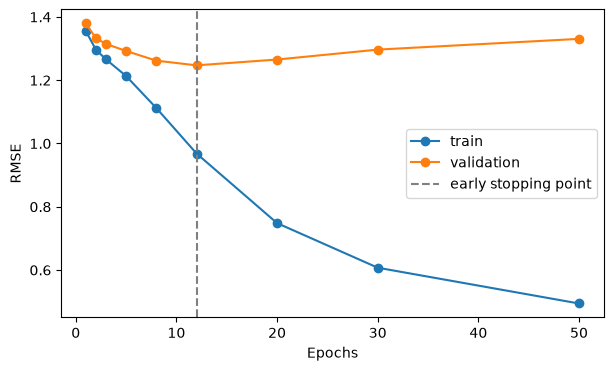

In [31]:
epochs_list = [1, 2, 3, 5, 8, 12, 20, 30, 50]
train_testset = tune_trainset.build_testset()

rows = []
for n_epochs in epochs_list:
    algo = SVD(n_factors=best_n_factors, n_epochs=n_epochs, random_state=my_seed)
    algo.fit(tune_trainset)
    rows.append({"epochs": n_epochs,
                 "train RMSE": accuracy.rmse(algo.test(train_testset), verbose=False),
                 "validation RMSE": accuracy.rmse(algo.test(tune_valset), verbose=False)})
epochs_df = pd.DataFrame(rows)

best_epochs = int(epochs_df.loc[epochs_df["validation RMSE"].idxmin(), "epochs"])
print("Epochs with the lowest validation RMSE:", best_epochs)

plt.figure(figsize=(7, 4))
plt.plot(epochs_df["epochs"], epochs_df["train RMSE"], marker="o", label="train")
plt.plot(epochs_df["epochs"], epochs_df["validation RMSE"], marker="o", label="validation")
plt.axvline(best_epochs, color="grey", linestyle="--", label="early stopping point")
plt.xlabel("Epochs")
plt.ylabel("RMSE")
plt.legend()
plt.show()

**Interpretation.** 

The train error falls with every epoch, from about 1.35 after one epoch to about 0.49 after 50, but the validation error only improves until 12 epochs (RMSE about 1.245) and then rises to about 1.33. After 12 epochs the model is fitting the noise in the training ratings instead of the users’ taste, which is overfitting. Training stops at 12 epochs, which is also better than the default of 20 (about 1.265). The epochs tested are 8, 12 and 20, so the best point lies somewhere between 8 and 20.

Latent factor 

In [33]:
svd_2d = SVD(n_factors=2, n_epochs=20, random_state=my_seed)
svd_2d.fit(trainset)

item_factors = pd.DataFrame(svd_2d.qi, columns=["dim 1", "dim 2"],
                            index=[trainset.to_raw_iid(i) for i in range(trainset.n_items)])
n_ratings = ratings_per_anime_df["count"].reindex(item_factors.index)

# Only anime with enough ratings, as the factors of rarely rated anime are not reliable
popular_factors = item_factors[n_ratings >= 200]
genres_popular = genres_df.reindex(popular_factors.index).fillna(0)
genre_corr = pd.DataFrame({dim: genres_popular.corrwith(popular_factors[dim]) for dim in popular_factors.columns}).dropna()

print("Anime in the plot:", len(popular_factors))
for dim in genre_corr.columns:
    ordered = genre_corr[dim].sort_values()
    print(dim, "- most negative genres:", list(ordered.index[:3]), " most positive genres:", list(ordered.index[-3:]))

Anime in the plot: 1168
dim 1 - most negative genres: ['Drama', 'Psychological', 'Mystery']  most positive genres: ['Harem', 'Ecchi', 'Comedy']
dim 2 - most negative genres: ['Harem', 'Ecchi', 'Romance']  most positive genres: ['Drama', 'Psychological', 'Dementia']


In [34]:
print(genre_corr.loc[["Drama", "Psychological", "Mystery", "Harem", "Ecchi", "Comedy", "Romance"]].round(2))
print("Correlation between the two factors:", round(popular_factors["dim 1"].corr(popular_factors["dim 2"]), 2))

               dim 1  dim 2
Drama          -0.28   0.17
Psychological  -0.25   0.18
Mystery        -0.22   0.10
Harem           0.24  -0.36
Ecchi           0.30  -0.36
Comedy          0.31  -0.01
Romance        -0.02  -0.22
Correlation between the two factors: -0.24


Latent factor plot

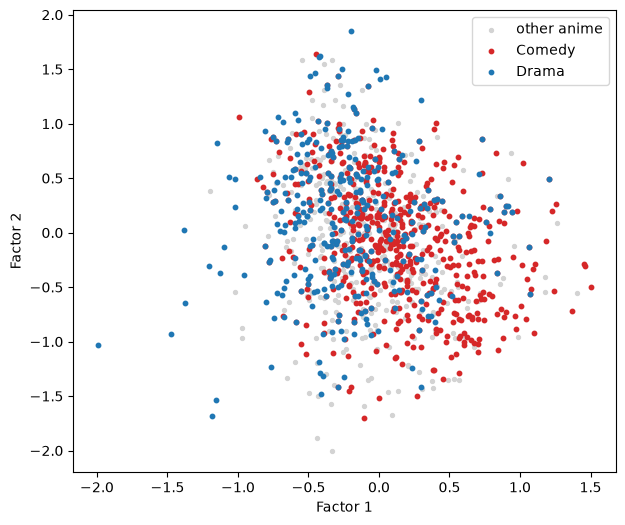

dim 1 low end:  ['School Days', 'Elfen Lied', 'Hoshi no Koe', 'Tenshi Kinryouku', 'Re:Zero kara Hajimeru Isekai Seikatsu']
dim 1 high end: ['Kiss x Sis (TV)', 'Aki-Sora: Yume no Naka', 'Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houjou Dattebayo! Special: Konoha Annual Sports Festival', 'Naruto', 'Dragon Ball GT']
dim 2 low end:  ['Sword Art Online', 'Diabolik Lovers', 'Isekai wa Smartphone to Tomo ni.', 'Tokyo Ghoul √A', 'Seiken Tsukai no World Break']
dim 2 high end: ['Mononoke', 'Neon Genesis Evangelion: The End of Evangelion', 'Serial Experiments Lain', 'Yojouhan Shinwa Taikei', 'Texhnolyze']


In [35]:
genre_a = genre_corr["dim 1"].idxmax()
genre_b = genre_corr["dim 1"].idxmin()

plt.figure(figsize=(7, 6))
plt.scatter(popular_factors["dim 1"], popular_factors["dim 2"], s=8, color="lightgrey", label="other anime")
for genre, color in [(genre_a, "tab:red"), (genre_b, "tab:blue")]:
    in_genre = genres_popular[genre] == 1
    plt.scatter(popular_factors.loc[in_genre, "dim 1"], popular_factors.loc[in_genre, "dim 2"], s=10, color=color, label=genre)
plt.xlabel("Factor 1")
plt.ylabel("Factor 2")
plt.legend()
plt.show()

# The anime at the two ends of each factor
for dim in ["dim 1", "dim 2"]:
    ordered = popular_factors[dim].sort_values()
    print(dim, "low end: ", [titles[i] for i in ordered.index[:5]])
    print(dim, "high end:", [titles[i] for i in ordered.index[-5:]])

**Interpretation** 
The two factors place Comedy and Drama anime in different parts of the plane: Comedy anime lean toward the lower right and Drama anime toward the upper left. The groups overlap heavily, so two dimensions capture only the broadest difference in taste, between serious and light anime, and much of what users like depends on other things. The model was never given the genres, so the separation comes only from which anime the same users rated highly. The two factors describe the same contrast along a diagonal, which is why the strongest genres for factor 2 mirror those for factor 1. The sign and rotation of the axes are arbitrary.

NMF

In [36]:
nmf_tuning = pd.DataFrame([
    dict({"n_factors": n_factors}, **validate(NMF(n_factors=n_factors, random_state=my_seed)))
    for n_factors in [1, 15, 100]
])
print(nmf_tuning.round(3).to_string(index=False))
best_nmf_factors = int(nmf_tuning.sort_values("NDCG@10", ascending=False).iloc[0]["n_factors"])

 n_factors  RMSE  NDCG@10  MAP@10
         1 4.517    0.948   0.805
        15 2.155    0.943   0.787
       100 2.668    0.911   0.670


In [37]:
best_nmf_factors = 15  # 1 factor is a popularity ranking; the NDCG gap to 15 is within noise

**Interpretation** 
NMF predicts ratings much worse than SVD (RMSE 2.2 against 1.26 at best). Surprise’s NMF has no global mean or bias terms and has to rebuild every rating from non-negative factors, so its scores are on the wrong scale even when the order of the anime is reasonable. Its NDCG (0.943 to 0.948) is close to SVD’s. A very large number of factors overfits (100 factors: NDCG 0.911, MAP 0.670). One factor scores highest on NDCG, but it only reproduces popularity, and the difference from 15 factors is within what one validation split can resolve, so the default of 15 is kept. NMF is not expected to be the final choice for rating prediction.

Final comparison and baseline

In [38]:
cf_models = {
    "User KNN": KNNBaseline(k=int(best_user["k"]), min_k=min(int(best_user["k"]), 5), verbose=False,
                            sim_options={"name": "cosine", "user_based": True, "min_support": int(best_user["min_support"])}),
    "Item KNN": KNNBaseline(k=int(best_item["k"]), min_k=min(int(best_item["k"]), 5), verbose=False,
                            sim_options={"name": "cosine", "user_based": False, "min_support": int(best_item["min_support"])}),
    "SVD": SVD(n_factors=best_n_factors, n_epochs=best_epochs, random_state=my_seed),
    "NMF": NMF(n_factors=best_nmf_factors, random_state=my_seed),
}

results_cf = {name: evaluate_model(algo) for name, algo in cf_models.items()}
results_part3_df = pd.concat([results_part2_df, pd.DataFrame(results_cf).T])
results_part3_df.round(3)

**Final comparison** SVD is the best model on rating accuracy (RMSE 1.23 against 1.55 for popularity) and on ranking within each user’s test items (NDCG@10 over users with 20+ test items: 0.922 against 0.912). It also gives the broadest and most personalised recommendations (coverage 7.3%, personalization 0.81). On the more demanding homepage test, though, Bayesian popular places 0.88 relevant titles in a user’s top 10 and reaches 49% of users, against 0.57 and 33% for SVD, because most users end up watching popular anime. The neighbourhood models use `KNNBaseline`, because `KNNWithMeans` ranks anime with a single rating of 10 first (see the KNN tuning section). NMF is the weakest personalised model, as Surprise’s version has no bias terms. The business trade-off is that popularity is the safer homepage default, while SVD adds personalisation and catalogue coverage.

# Part 4. Content-based

Content-based recommenders use the anime metadata instead of the ratings of other users [1, p. 139]. This part first compares ways to represent an anime as a vector: numerical features, categorical features, Bag of Words, TF-IDF, lemmatized TF-IDF, Sentence-BERT and named entities. Each representation gives a similarity between every pair of anime. The data is `anime_df` from Part 1.

## Prepare the anime catalogue

In [49]:
import re
from collections import Counter
from itertools import combinations

import nltk
from nltk.stem import WordNetLemmatizer
from scipy.sparse import hstack, csr_matrix
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer, OneHotEncoder
from surprise import PredictionImpossible
from transformers import pipeline

In [2]:
# The catalogue from Part 1. The ratings and users are not needed here
anime = anime_df.copy().reset_index(drop=True)
print("Anime:", anime.shape)
display(anime.head())

In [9]:
print(anime.columns.tolist())
print(anime.dtypes)
missing = anime.isna().sum()
display(pd.DataFrame({"Missing": missing, "Percent": (missing / len(anime) * 100).round(2)}).sort_values("Missing", ascending=False))
expected_columns = ["anime_id", "title", "type", "genre", "episodes", "synopsis"]
print("Required columns present:", all(c in anime.columns for c in expected_columns))
print("Duplicate anime IDs:", anime["anime_id"].duplicated().sum())
print("Duplicate titles:", anime["title"].duplicated().sum())

['anime_id', 'title', 'type', 'source', 'episodes', 'rating', 'score', 'scored_by', 'popularity', 'members', 'studio', 'genre', 'duration_min', 'aired_from_year', 'synopsis', 'synopsis_length']
anime_id             int64
title                  str
type                   str
source                 str
episodes             int64
rating                 str
score              float64
scored_by            int64
popularity           int64
members              int64
studio                 str
genre                  str
duration_min       float64
aired_from_year    float64
synopsis               str
synopsis_length      int64
dtype: object


,Missing,Percent
synopsis,345,5.17
rating,82,1.23
genre,4,0.06
anime_id,0,0.00
source,0,0.00
episodes,0,0.00
type,0,0.00
title,0,0.00
scored_by,0,0.00
score,0,0.00


Required columns present: True
Duplicate anime IDs: 0
Duplicate titles: 0


Average synopsis length: 83.64457108578284
Median synopsis length: 75.0
Empty synopses: 345
Short synopses (under 30 words): 1807


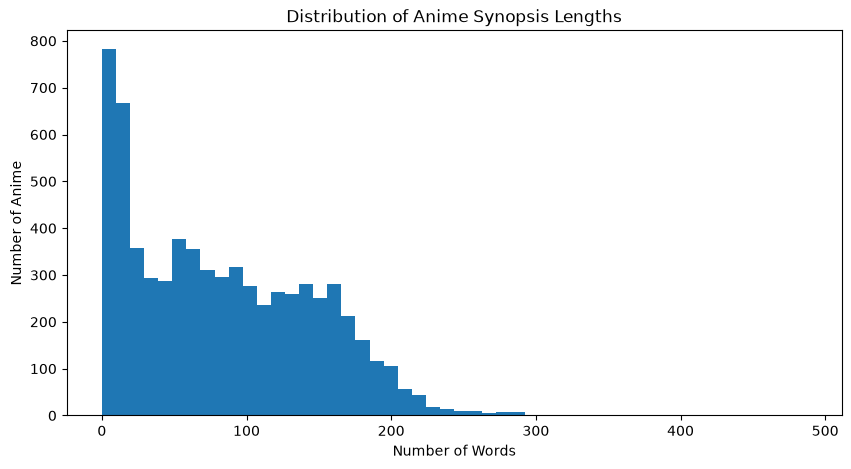

In [8]:
anime["synopsis_length"] = ( anime["synopsis"] .fillna("")  .str.split() .str.len())
print("Average synopsis length:", anime["synopsis_length"].mean())
print("Median synopsis length:",anime["synopsis_length"].median())
print("Empty synopses:",(anime["synopsis_length"] == 0).sum())
print("Short synopses (under 30 words):",(anime["synopsis_length"] < 30).sum())

plt.figure(figsize=(10, 5))
plt.hist(
    anime["synopsis_length"],bins=50)
plt.title("Distribution of Anime Synopsis Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Anime")

plt.show()

In [5]:
anime_clean = anime.copy().reset_index(drop=True)
print("Original dataset:", anime.shape)
print("Working dataset:", anime_clean.shape)

Original dataset: (6668, 15)
Working dataset: (6668, 15)


In [4]:

anime_clean["synopsis"] = anime_clean["synopsis"].fillna("")
anime_clean["genre"] = anime_clean["genre"].fillna("")
anime_clean["studio"] = anime_clean["studio"].fillna("")

print(anime_clean[["synopsis", "genre", "studio"]].isnull().sum())

Original dataset: (6668, 15)
Working dataset: (6668, 15)
synopsis    0
genre       0
studio      0
dtype: int64


In [10]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

for col in ["title", "genre", "synopsis"]:
    anime_clean[col + "_clean"] = anime_clean[col].apply(clean_text)
anime_clean["content"] = anime_clean[["title_clean", "genre_clean", "synopsis_clean"]].agg(" ".join, axis=1)
display(anime_clean[["title", "genre", "content"]].head())

,title,genre,content
0,Inu x Boku SS,"Comedy, Supernatural, Romance, Shounen",inu x boku ss comedy supernatural romance shou...
1,Seto no Hanayome,"Comedy, Parody, Romance, School, Shounen",seto no hanayome comedy parody romance school ...
2,Shugo Chara!! Doki,"Comedy, Magic, School, Shoujo",shugo chara doki comedy magic school shoujo no...
3,Princess Tutu,"Comedy, Drama, Magic, Romance, Fantasy",princess tutu comedy drama magic romance fanta...
4,Bakuman. 3rd Season,"Comedy, Drama, Romance, Shounen",bakuman 3rd season comedy drama romance shoune...


**Data & Sypnosis:**
We found 345 missing synopses (5.17%), 4 missing genres (0.06%), and 82 missing content ratings (1.23%). We filled missing text fields with empty strings without removing anime, then counted synopsis words. Results showed an average of about 83.6 words, a median of 75 words, 345 empty synopses, and 1,807 synopses under 30 words. We lowercased text, removed punctuation, normalized spaces, and combined title + genre + synopsis into one content field. Removing the punctuations and capitalization may be a trade off but this is kept for the original title and sypnosis for display and NER

Implication: titles with no synopsis have less text information, so BoW, TF-IDF, and BERT may depend disproportionately on title and genre. Short or missing descriptions may make content recommendations less reliable for some titles.


## Numerical similarity

In [11]:
num_columns = ["episodes", "duration_min", "aired_from_year"]
anime_num = anime_clean[num_columns].apply(pd.to_numeric, errors="coerce")
display(anime_num.describe())
print("Missing values:\n", anime_num.isna().sum())

,episodes,duration_min,aired_from_year
count,6668.000000,6668.000000,6668.000000
mean,14.276395,28.442167,2006.915267
std,40.906929,25.365980,10.381425
min,0.000000,0.000000,1942.000000
25%,1.000000,17.000000,2003.000000
50%,6.000000,24.000000,2010.000000
75%,13.000000,27.000000,2015.000000
max,1818.000000,163.000000,2018.000000


Missing values:
 episodes           0
duration_min       0
aired_from_year    0
dtype: int64
Raw: (6668, 6668) Scaled: (6668, 6668)


In [12]:
anime_num = anime_num.fillna(anime_num.median())
num_distance = euclidean_distances(anime_num)
scaler = StandardScaler()
anime_num_scaled = scaler.fit_transform(anime_num)
num_distance_scaled = euclidean_distances(anime_num_scaled)
print("Raw:", num_distance.shape, "Scaled:", num_distance_scaled.shape)

Raw: (6668, 6668) Scaled: (6668, 6668)


In [ ]:
anime_clean.describe()

**Numerical features: interpretation**

The earlier statistics showed large differences in scale: episodes ranged from 0 to 1,818, duration from 0 to 163 minutes, and year from 1942 to 2018. Zero values may represent missing/unknown metadata, not necessarily true zero-length content.

In both distance matrices, smaller values mean closer items. Unlike cosine similarity, these are not scores where larger means better.

In [14]:
def title_index(title):
    matches = anime_clean.index[anime_clean["title"].str.casefold() == title.casefold()]
    if len(matches) == 0:
        raise ValueError(f"Anime not found: {title}")
    return int(matches[0])

def recommend_from_matrix(title, matrix, top_n=10, distance=False, columns=None):
    idx = title_index(title)
    scores = pd.Series(matrix[idx]).drop(idx)
    scores = scores.nsmallest(top_n) if distance else scores.nlargest(top_n)
    columns = columns or ["title", "genre"]
    result = anime_clean.iloc[scores.index][columns].copy()
    result["distance" if distance else "similarity"] = scores.to_numpy().round(4)
    return result.reset_index(drop=True)

raw = recommend_from_matrix("Death Note", num_distance, distance=True, columns=["title", *num_columns])
scaled = recommend_from_matrix("Death Note", num_distance_scaled, distance=True, columns=["title", *num_columns])
display(pd.DataFrame({"Without normalization": raw["title"], "Raw distance": raw["distance"], "With normalization": scaled["title"], "Scaled distance": scaled["distance"]}))

,Without normalization,Raw distance,With normalization,Scaled distance
0,Gallery Fake,2.2361,Otogi Juushi Akazukin,0.0628
1,Otogi Juushi Akazukin,2.2361,Saiunkoku Monogatari,0.0928
2,Yuki no Joou (TV),2.4495,Gallery Fake,0.1245
3,Saiunkoku Monogatari,2.8284,Yuki no Joou (TV),0.1269
4,Saiunkoku Monogatari 2nd Season,3.0000,Saiunkoku Monogatari 2nd Season,0.1337
5,Kyou kara Maou! 3rd Series,3.0000,Kyou kara Maou! 3rd Series,0.2026
6,Agatha Christie no Meitantei Poirot to Marple,3.4641,Agatha Christie no Meitantei Poirot to Marple,0.2138
7,Mermaid Melody Pichi Pichi Pitch Pure,3.4641,Mermaid Melody Pichi Pichi Pitch Pure,0.2138
8,Hanasakeru Seishounen,3.7417,Nana,0.2445
9,Element Hunters,3.7417,Tengen Toppa Gurren Lagann,0.2657


**Numerical recommendations: interpretation**
The side-by-side table shows how standardization changes which titles rank highest. Normalization is important when combining numeric attributes, but these recommendations mainly describe format and age, not plot or themes. A numerical match is not necessarily a good content recommendation.

The raw and normalized top-10 lists for Death Note differed, confirming that scaling changes the ranking.

## Categorical similarity

In [19]:
cat_columns = ["genre", "type", "source", "studio"]
anime_cat = anime_clean[cat_columns].copy()
for col in cat_columns:
    print(col, "unique values:", anime_cat[col].nunique())

genres = anime_cat["genre"].fillna("").astype(str).str.split(", ")
mlb = MultiLabelBinarizer()
genre_matrix = csr_matrix(mlb.fit_transform(genres))
encoder = OneHotEncoder(handle_unknown="ignore")
other_matrix = encoder.fit_transform(anime_cat[["type", "source", "studio"]])
cat_matrix = hstack([genre_matrix, other_matrix]).tocsr()
cat_similarity = cosine_similarity(cat_matrix)
print("Categorical matrix:", cat_matrix.shape)
print("Number of genres:", len(mlb.classes_))
display(recommend_from_matrix("Death Note", cat_similarity, columns=["title", *cat_columns]))

genre unique values: 3203
type unique values: 6
source unique values: 15
studio unique values: 711
Categorical matrix: (6668, 776)
Number of genres: 44


,title,genre,type,source,studio,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",Special,Manga,Madhouse,0.8250
1,Mirai Nikki (TV),"Action, Psychological, Supernatural, Thriller,...",TV,Manga,Asread,0.7778
2,Monster,"Drama, Horror, Mystery, Police, Psychological,...",TV,Manga,Madhouse,0.7379
3,Mousou Dairinin,"Mystery, Dementia, Police, Psychological, Supe...",TV,Original,Madhouse,0.7379
4,Majin Tantei Nougami Neuro,"Mystery, Comedy, Demons, Supernatural, Shounen",TV,Manga,Madhouse,0.7071
5,Mouryou no Hako,"Mystery, Psychological, Supernatural, Thriller...",TV,Novel,Madhouse,0.7071
6,Top Secret: The Revelation,"Sci-Fi, Mystery, Police, Psychological, Shoujo",TV,Manga,Madhouse,0.7071
7,Higurashi no Naku Koro ni Kai,"Mystery, Psychological, Supernatural, Thriller",TV,Visual novel,Studio Deen,0.6299
8,Touhai Densetsu Akagi: Yami ni Maiorita Tensai,"Game, Psychological, Thriller, Seinen",TV,Manga,Madhouse,0.6299
9,Gyakkyou Burai Kaiji: Hakairoku-hen,"Game, Psychological, Thriller, Seinen",TV,Manga,Madhouse,0.6299


**Categorical features: interpretation**

There are 44 genres with multilabel indicators because anime can belong to multiple genres using encoding of type, source and studio separately. The matrix has 6,668 rows × 776 features, and the cosine similarity matrix has 6,668 × 6,668 entries.
Explicit metadata may have produced more related titles than numerical similarity. Every encoded indicator contributes equally.

 Death Note: Rewrite (0.8250), Mirai Nikki (TV) (0.7778), Monster (0.7379), and Mousou Dairinin (0.7379) ranked highly. These choices share genres such as psychological, mystery, or supernatural, while some also share a studio. Sharing a studio can affect the score even if stories differ.



## Bag of Words

In [21]:
bow_vectorizer = CountVectorizer(stop_words="english", max_features=10000)
bow_matrix = bow_vectorizer.fit_transform(anime_clean["content"])
bow_similarity = cosine_similarity(bow_matrix)

print("BoW matrix shape:", bow_matrix.shape)
display(recommend_from_matrix("Death Note", bow_similarity))

BoW matrix shape: (6668, 10000)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.4121
1,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.3119
2,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2667
3,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.2526
4,Kite Liberator,"Action, Sci-Fi, Drama",0.2484
5,Death Parade,"Game, Mystery, Psychological, Drama, Thriller",0.2434
6,Persona 3 the Movie 4: Winter of Rebirth,"Action, Supernatural, Fantasy",0.2066
7,Da Yu Hai Tang,"Adventure, Drama, Romance, Supernatural",0.2047
8,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.2047
9,Zombie-Loan,"Action, Horror, Shounen, Supernatural",0.2022


## TF-IDF

In [22]:
tfidf_vectorizer = TfidfVectorizer(stop_words="english", max_features=10000)
tfidf_matrix = tfidf_vectorizer.fit_transform(anime_clean["content"])
tfidf_similarity = cosine_similarity(tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
display(recommend_from_matrix("Death Note", tfidf_similarity))

TF-IDF matrix shape: (6668, 10000)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.3574
1,Soushisouai Note The Animation,Hentai,0.2655
2,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.2207
3,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2153
4,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.2107
5,Kite Liberator,"Action, Sci-Fi, Drama",0.1709
6,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.1652
7,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.1619
8,Death Parade,"Game, Mystery, Psychological, Drama, Thriller",0.1437
9,Bleach: Memories in the Rain,"Action, Adventure, Supernatural, Drama, Shounen",0.1427


In [24]:
bow_top10 = recommend_from_matrix("Death Note", bow_similarity)
tfidf_top10 = recommend_from_matrix("Death Note", tfidf_similarity)

comparison = pd.merge(
    bow_top10[["title", "similarity"]],
    tfidf_top10[["title", "similarity"]],
    on="title",
    how="outer",
    suffixes=("_bow", "_tfidf"))

comparison.columns = ["Anime", "Bag of Words", "TF-IDF"]
comparison = comparison.sort_values(
    by="Bag of Words",
    ascending=False,
    na_position="last")

display(comparison.round(4))

,Anime,Bag of Words,TF-IDF
2,Death Note: Rewrite,0.4121,0.3574
8,Soul Eater,0.3119,0.2107
7,Shinigami no Ballad.,0.2667,0.2153
4,Dia Horizon (Kabu),0.2526,0.1652
5,Kite Liberator,0.2484,0.1709
3,Death Parade,0.2434,0.1437
6,Persona 3 the Movie 4: Winter of Rebirth,0.2066,NaN
1,Da Yu Hai Tang,0.2047,NaN
10,YAT Anshin! Uchuu Ryokou 2,0.2047,0.2207
12,Zombie-Loan,0.2022,NaN


**BoW versus TF-IDF: interpretation**

Both vectorizers produced 6,668 × 10,000 item-feature matrices in the earlier run. BoW counts words. TF-IDF reduces the influence of words across many anime descriptions.

For Death Note, both methods placed Death Note: Rewrite first. But TF-IDF also ranked Soushisouai Note The Animation highly (0.2938), shared words like  "Note" can cause an irrelevant match. This needs to be looked into as this is a Hentai Genre.
Text-based methods are useful baselines, but word overlap alone cannot guarantee thematic relevance.

## Lemmatized TF-IDF

In [25]:
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    return " ".join(lemmatizer.lemmatize(word) for word in text.split())

anime_clean["synopsis_lem"] = anime_clean["synopsis_clean"].apply(lemmatize_text)
anime_clean["content_lem"] = anime_clean[["title_clean", "genre_clean", "synopsis_lem"]].agg(" ".join, axis=1)
tfidf_lem_vectorizer = TfidfVectorizer(stop_words="english", max_features=10000)
tfidf_lem_matrix = tfidf_lem_vectorizer.fit_transform(anime_clean["content_lem"])
tfidf_lem_similarity = cosine_similarity(tfidf_lem_matrix)
print("Lemmatized TF-IDF:", tfidf_lem_matrix.shape)
display(recommend_from_matrix("Death Note", tfidf_lem_similarity))

Lemmatized TF-IDF: (6668, 10000)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.3488
1,Soushisouai Note The Animation,Hentai,0.2580
2,Shinigami no Ballad.,"Drama, Fantasy, Psychological, Supernatural",0.2391
3,YAT Anshin! Uchuu Ryokou 2,"Adventure, Comedy, Sci-Fi, Shounen",0.2268
4,Soul Eater,"Action, Fantasy, Comedy, Supernatural, Shounen",0.1887
5,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.1810
6,Kite Liberator,"Action, Sci-Fi, Drama",0.1649
7,Dia Horizon (Kabu),"Action, Adventure, Magic, Fantasy",0.1626
8,Burn Up Scramble,"Action, Comedy, Drama, Ecchi, Police, Sci-Fi, ...",0.1583
9,Wild 7,"Action, Police, Drama, Shounen",0.1437


**Lemmatization: interpretation**

The lemmatization is done only on the sypnosis using a noun base WordNet lemmatizer. leaving title and genre labels. Reducing word variants can change similarity rankings, but it does not automatically improve recommendation relevance.

TF-IDF  produced 6,668 × 10,000 features and ranked Death Note: Rewrite first (0.3319). The irrelevant Soushisouai Note The Animation remained second (0.2879), so lemmatization did not resolve that mismatch.

## Sentence-BERT semantic similarity

In [27]:
model = SentenceTransformer("all-MiniLM-L6-v2")
bert_embeddings = model.encode(anime_clean["content"].tolist(), batch_size=32, show_progress_bar=True, convert_to_numpy=True)
bert_similarity = cosine_similarity(bert_embeddings)
print("Embeddings:", bert_embeddings.shape, "Similarity:", bert_similarity.shape)
display(recommend_from_matrix("Death Note", bert_similarity))

Batches: 100%|██████████| 209/209 [01:01<00:00,  3.40it/s]


Embeddings: (6668, 384) Similarity: (6668, 6668)


,title,genre,similarity
0,Death Note: Rewrite,"Mystery, Police, Psychological, Supernatural, ...",0.6631
1,Yami no Matsuei,"Comedy, Drama, Fantasy, Horror, Magic, Shoujo,...",0.6184
2,Majin Tantei Nougami Neuro,"Mystery, Comedy, Demons, Supernatural, Shounen",0.5847
3,Yakushiji Ryouko no Kaiki Jikenbo,"Mystery, Police, Supernatural",0.5759
4,Kara no Kyoukai 7: Satsujin Kousatsu (Kou),"Action, Mystery, Supernatural, Romance, Thriller",0.5747
5,Angel Cop,"Action, Sci-Fi, Police",0.5692
6,Shinrei Tantei Yakumo,"Horror, Mystery, Shoujo, Supernatural",0.5691
7,UN-GO,"Mystery, Supernatural",0.5572
8,Yami Shibai,"Dementia, Horror, Demons, Supernatural",0.5568
9,ChäoS;HEAd,"Harem, Mystery, Psychological, Sci-Fi, Superna...",0.5533


**Sentence-BERT: interpretation**

The  all-MiniLM-L6-v2 model results showed an embedding matrix and an item similarity matrix. Semantic embeddings offer an alternative to word-count approaches. They have not yet been validated against user preferences. A higher BERT cosine score is not directly comparable to a BoW or TF-IDF score.

For Death Note, the BERT ranking included Death Note: Rewrite (0.6631), Yami no Matsuei (0.6184), and Majin Tantei Nougami Neuro (0.5847). These results suggest BERT can surface thematic matches that do not rely solely on identical title words.


## Comparison

In [28]:
methods = {"BoW": bow_similarity, "TF-IDF": tfidf_similarity, "Lemmatized TF-IDF": tfidf_lem_similarity, "BERT": bert_similarity}
comparison = pd.DataFrame()
for name, matrix in methods.items():
    result = recommend_from_matrix("Death Note", matrix)
    comparison[name] = result["title"]
    comparison[name + " score"] = result["similarity"]
comparison.index = range(1, len(comparison) + 1)
display(comparison)

,BoW,BoW score,TF-IDF,TF-IDF score,Lemmatized TF-IDF,Lemmatized TF-IDF score,BERT,BERT score
1,Death Note: Rewrite,0.4121,Death Note: Rewrite,0.3574,Death Note: Rewrite,0.3488,Death Note: Rewrite,0.6631
2,Soul Eater,0.3119,Soushisouai Note The Animation,0.2655,Soushisouai Note The Animation,0.2580,Yami no Matsuei,0.6184
3,Shinigami no Ballad.,0.2667,YAT Anshin! Uchuu Ryokou 2,0.2207,Shinigami no Ballad.,0.2391,Majin Tantei Nougami Neuro,0.5847
4,Dia Horizon (Kabu),0.2526,Shinigami no Ballad.,0.2153,YAT Anshin! Uchuu Ryokou 2,0.2268,Yakushiji Ryouko no Kaiki Jikenbo,0.5759
5,Kite Liberator,0.2484,Soul Eater,0.2107,Soul Eater,0.1887,Kara no Kyoukai 7: Satsujin Kousatsu (Kou),0.5747
6,Death Parade,0.2434,Kite Liberator,0.1709,Yami no Matsuei,0.1810,Angel Cop,0.5692
7,Persona 3 the Movie 4: Winter of Rebirth,0.2066,Dia Horizon (Kabu),0.1652,Kite Liberator,0.1649,Shinrei Tantei Yakumo,0.5691
8,Da Yu Hai Tang,0.2047,Yami no Matsuei,0.1619,Dia Horizon (Kabu),0.1626,UN-GO,0.5572
9,YAT Anshin! Uchuu Ryokou 2,0.2047,Death Parade,0.1437,Burn Up Scramble,0.1583,Yami Shibai,0.5568
10,Zombie-Loan,0.2022,Bleach: Memories in the Rain,0.1427,Wild 7,0.1437,ChäoS;HEAd,0.5533


**Model comparison: interpretation**

Across the earlier Death Note examples, Death Note: Rewrite ranked first in all four text approaches. The rest of the rankings differed considerably.

Agreement on an obvious sequel is encouraging but not enough to select a model. Comparing raw cosine values across methods would be misleading.

## Named Entity Recognition (exploratory)

Uses Hugging Face rather than spaCy because spaCy imports were blocked by Windows application control. NER trained on general English can misidentify Japanese names and split words into fragments.

In [29]:
ner = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple")
text = anime_clean.loc[title_index("Death Note"), "synopsis"]
display(pd.DataFrame(ner(text[:1500]))[["word", "entity_group", "score"]])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 931.80it/s]
[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,word,entity_group,score
0,Death Note,MISC,0.895889
1,R,PER,0.997150
2,##yu,PER,0.995996
3,##k,PER,0.832990
4,Death Note,MISC,0.940506
5,Light Yagami,PER,0.854752
6,Death Note,MISC,0.912459
7,Death Note,MISC,0.939820
8,Light,PER,0.998398
9,Light,PER,0.998350


**NER demonstration: interpretation**

NER was first tested on the synopsis of Death Note which extracts names of people, organizations, locations, and other named entities from it. In the earlier Death Note example, the model recognized terms such as Death Note and Light Yagami, but also split names into fragments such as ##yu and ##k. These are signs of tokenization or entity-recognition errors.

NER might help identify shared characters or settings, but a general English model is not optimized for Japanese anime names. The extracted entities require cleaning before they can be used reliably in content-based recommendations.

In [31]:
texts = anime_clean["synopsis"].fillna("").astype(str).tolist()

texts = [
    ner.tokenizer.decode(
        ner.tokenizer.encode(
            text,
            truncation=True,
            max_length=512
        ),
        skip_special_tokens=True
    )
    for text in texts]

ner_results = ner(texts, batch_size=16)

anime_clean["NER"] = [
    [
        (e["word"], e["entity_group"], round(float(e["score"]), 3))
        for e in entities
    ]
    for entities in ner_results]

display(anime_clean[["title", "synopsis", "NER"]].head(10))

,title,synopsis,NER
0,Inu x Boku SS,chiyo Shirakiin is the sheltered daughter of a...,"[(ch, PER, 0.603), (Shirak, PER, 0.76), (R, PE..."
1,Seto no Hanayome,"During his summer vacation, middle school stud...","[(Nagasumi Michishi, PER, 0.791), (Seto Inland..."
2,Shugo Chara!! Doki,Now Utau has left Easter and restarted her sin...,"[(U, PER, 0.998), (##u, PER, 0.653), (Easter, ..."
3,Princess Tutu,"In a fairy tale come to life, the clumsy, swee...","[(Ah, PER, 0.998), (Japanese, MISC, 0.996), (A..."
4,Bakuman. 3rd Season,"Onto their third serialization, manga duo Mori...","[(On, ORG, 0.606), (Mo, PER, 0.998), (##rita, ..."
5,Yume-iro Pâtissière,"side from her deep passion for eating cakes, t...","[(I, PER, 0.999), (##chi, PER, 0.9), (##go Ama..."
6,Ultra Maniac,Fantasies and miracles never interested Ayu Ta...,"[(A, PER, 0.999), (##yu Tateishi, PER, 0.978),..."
7,Shakugan no Shana II (Second),Denizens from the Crimson Realm continue to in...,"[(Crimson Realm, LOC, 0.736), (Misaki City, LO..."
8,Nodame Cantabile: Paris-hen,"Shinichi Chiaki conquers his fear of flying, a...","[(Shin, PER, 1.0), (##ichi Chiaki, PER, 0.974)..."
9,Ouran Koukou Host Club,Haruhi Fujioka is a bright scholarship candida...,"[(Ha, PER, 0.999), (##ru, PER, 0.702), (Fujiok..."


In [33]:
generic_entities = {
    "japanese", "japan", "english",
    "earth", "world", "light"}

def clean_entities(entities):
    cleaned = set()
    for name, label, score in entities:
        name = name.strip()
        normalized = name.casefold()
        if score < 0.85:
            continue
        if len(name) < 3:
            continue
        if "##" in name:
            continue
        if normalized in generic_entities:
            continue
        cleaned.add((normalized, label))
    return sorted(cleaned)

anime_clean["NER_clean"] = anime_clean["NER"].apply(clean_entities)
display(anime_clean[["title", "NER", "NER_clean"]].head(10))
entity_types = Counter()
entity_frequency = Counter()

for entities in anime_clean["NER_clean"]:
    entity_types.update(label for name, label in entities)
    entity_frequency.update(entities)

print("Entity types:", entity_types)
print("Anime with entities:", anime_clean["NER_clean"].apply(bool).sum())
print("Anime without entities:", anime_clean["NER_clean"].apply(bool).eq(False).sum())

display(pd.DataFrame(
    entity_frequency.most_common(20),
    columns=["Entity", "Anime Count"]))

,title,NER,NER_clean
0,Inu x Boku SS,"[(ch, PER, 0.603), (Shirak, PER, 0.76), (R, PE...","[(maison de ayakashi, LOC), (miketsuka, PER), ..."
1,Seto no Hanayome,"[(Nagasumi Michishi, PER, 0.791), (Seto Inland...","[(mio sun beach, LOC), (seto inland sea, LOC),..."
2,Shugo Chara!! Doki,"[(U, PER, 0.998), (##u, PER, 0.653), (Easter, ...","[(easter, PER), (guardians, ORG), (lulu, PER),..."
3,Princess Tutu,"[(Ah, PER, 0.998), (Japanese, MISC, 0.996), (A...",[]
4,Bakuman. 3rd Season,"[(On, ORG, 0.606), (Mo, PER, 0.998), (##rita, ...","[(shounen jack, MISC)]"
5,Yume-iro Pâtissière,"[(I, PER, 0.999), (##chi, PER, 0.9), (##go Ama...","[(henri, PER), (henri lucas, PER), (st. marie ..."
6,Ultra Maniac,"[(A, PER, 0.999), (##yu Tateishi, PER, 0.978),...","[(holy stones, MISC), (magic kingdom, LOC), (n..."
7,Shakugan no Shana II (Second),"[(Crimson Realm, LOC, 0.736), (Misaki City, LO...","[(midnight lost child, MISC), (misaki city, LO..."
8,Nodame Cantabile: Paris-hen,"[(Shin, PER, 1.0), (##ichi Chiaki, PER, 0.974)...","[(charles auclair, PER), (chi, PER), (conserva..."
9,Ouran Koukou Host Club,"[(Ha, PER, 0.999), (##ru, PER, 0.702), (Fujiok...","[(fujioka, PER), (honey, PER), (host club, ORG..."


Entity types: Counter({'PER': 6436, 'MISC': 3652, 'ORG': 2772, 'LOC': 1978})
Anime with entities: 5140
Anime without entities: 1528


,Entity,Anime Count
0,"(tokyo, LOC)",196
1,"(blu, MISC)",162
2,"(shi, PER)",136
3,"(chi, PER)",128
4,"(shin, PER)",122
5,"(mal news, ORG)",65
6,"(ann, ORG)",62
7,"(shu, PER)",57
8,"(crunchyroll, ORG)",57
9,"(sato, PER)",51


In [34]:
def recommend_ner(anime_title, top_n=10, max_frequency=10):
    matches = anime_clean.index[anime_clean["title"] == anime_title]
    if len(matches) == 0:
        print("Anime not found.")
        return pd.DataFrame()
    idx = matches[0]
    target = {
        entity
        for entity in anime_clean.loc[idx, "NER_clean"]
        if entity_frequency[entity] <= max_frequency}
    results = []
    for i, row in anime_clean.iterrows():
        if i == idx:
            continue
        shared = target.intersection(row["NER_clean"])
        if shared:
            results.append({
                "title": row["title"],
                "genre": row["genre"],
                "shared_entities": len(shared),
                "entities": sorted(shared)})
    columns = ["title", "genre", "shared_entities", "entities"]

    return (
        pd.DataFrame(results, columns=columns)
        .sort_values("shared_entities", ascending=False)
        .head(top_n)
        .reset_index(drop=True))

display(recommend_ner("Death Note"))
ner_top10 = recommend_ner("Death Note")
bert_top10 = recommend_from_matrix("Death Note", bert_similarity)

comparison_ner = pd.DataFrame({
    "NER": ner_top10["title"].reindex(range(10)),
    "NER Shared Entities": ner_top10["shared_entities"].reindex(range(10)),
    "BERT": bert_top10["title"].reindex(range(10)),
    "BERT Similarity": bert_top10["similarity"].reindex(range(10))})
comparison_ner.index = range(1, 11)
display(comparison_ner)

,title,genre,shared_entities,entities


,NER,NER Shared Entities,BERT,BERT Similarity
1,NaN,NaN,Death Note: Rewrite,0.6631
2,NaN,NaN,Yami no Matsuei,0.6184
3,NaN,NaN,Majin Tantei Nougami Neuro,0.5847
4,NaN,NaN,Yakushiji Ryouko no Kaiki Jikenbo,0.5759
5,NaN,NaN,Kara no Kyoukai 7: Satsujin Kousatsu (Kou),0.5747
6,NaN,NaN,Angel Cop,0.5692
7,NaN,NaN,Shinrei Tantei Yakumo,0.5691
8,NaN,NaN,UN-GO,0.5572
9,NaN,NaN,Yami Shibai,0.5568
10,NaN,NaN,ChäoS;HEAd,0.5533


### NER vs. Sentence-BERT: Comparison

NER may identify direct connections through recurring characters or settings, BERT can identify anime with similar themes even when they do not share named entities. The two scores are not directly comparable: NER uses a count of shared entities, while BERT uses cosine similarity.

NER may be useful but the comparison does not establish that it improves recommendation accuracy.
The NER-based recommendation method failed to produce recommendations for Death Note, frequently divided Japanese character names into incomplete fragments, such as shi, chi, and shin.

The BERT successfully did. It identified anime such as Death Note: Rewrite, Yami no Matsuei, and Majin Tantei Nougami Neuro without requiring identical character names or locations.


The current NER approach is too restrictive and noisy to function as a reliable standalone recommender. This remains an exploratory feature as BERT is more effective and will be prioritized along with TF - IDF for the hyper parameter tuning and evaluation.



In [38]:

models = {
    "BoW": bow_similarity,
    "TF-IDF": tfidf_similarity,
    "Lemmatized TF-IDF": tfidf_lem_similarity,
    "Sentence-BERT": bert_similarity}

test_anime = [
    "Death Note",
    "Naruto",
    "Shingeki no Kyojin",
    "Fullmetal Alchemist: Brotherhood",
    "One Punch Man"]

test_anime = [
    title for title in test_anime
    if title in anime_clean["title"].values]

print("Models:", list(models))
print("Test anime:", test_anime)

Models: ['BoW', 'TF-IDF', 'Lemmatized TF-IDF', 'Sentence-BERT']
Test anime: ['Death Note', 'Naruto', 'Shingeki no Kyojin', 'Fullmetal Alchemist: Brotherhood', 'One Punch Man']


In [39]:
def compare_recommendations(title, top_n=10):
    comparison = pd.DataFrame()
    for name, matrix in models.items():
        recs = recommend_from_matrix(title, matrix, top_n=top_n)
        comparison[name] = [
            f"{anime} ({score:.4f})"
            for anime, score in zip(recs["title"], recs["similarity"])]
    comparison.index = range(1, top_n + 1)
    return comparison

display(compare_recommendations("Death Note"))

,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Death Note: Rewrite (0.4121),Death Note: Rewrite (0.3574),Death Note: Rewrite (0.3488),Death Note: Rewrite (0.6631)
2,Soul Eater (0.3119),Soushisouai Note The Animation (0.2655),Soushisouai Note The Animation (0.2580),Yami no Matsuei (0.6184)
3,Shinigami no Ballad. (0.2667),YAT Anshin! Uchuu Ryokou 2 (0.2207),Shinigami no Ballad. (0.2391),Majin Tantei Nougami Neuro (0.5847)
4,Dia Horizon (Kabu) (0.2526),Shinigami no Ballad. (0.2153),YAT Anshin! Uchuu Ryokou 2 (0.2268),Yakushiji Ryouko no Kaiki Jikenbo (0.5759)
5,Kite Liberator (0.2484),Soul Eater (0.2107),Soul Eater (0.1887),Kara no Kyoukai 7: Satsujin Kousatsu (Kou) (0....
6,Death Parade (0.2434),Kite Liberator (0.1709),Yami no Matsuei (0.1810),Angel Cop (0.5692)
7,Persona 3 the Movie 4: Winter of Rebirth (0.2066),Dia Horizon (Kabu) (0.1652),Kite Liberator (0.1649),Shinrei Tantei Yakumo (0.5691)
8,Da Yu Hai Tang (0.2047),Yami no Matsuei (0.1619),Dia Horizon (Kabu) (0.1626),UN-GO (0.5572)
9,YAT Anshin! Uchuu Ryokou 2 (0.2047),Death Parade (0.1437),Burn Up Scramble (0.1583),Yami Shibai (0.5568)
10,Zombie-Loan (0.2022),Bleach: Memories in the Rain (0.1427),Wild 7 (0.1437),ChäoS;HEAd (0.5533)


In [43]:
for title in test_anime[:3]:
    print("\n", title)
    display(compare_recommendations(title))


 Death Note


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Death Note: Rewrite (0.4121),Death Note: Rewrite (0.3574),Death Note: Rewrite (0.3488),Death Note: Rewrite (0.6631)
2,Soul Eater (0.3119),Soushisouai Note The Animation (0.2655),Soushisouai Note The Animation (0.2580),Yami no Matsuei (0.6184)
3,Shinigami no Ballad. (0.2667),YAT Anshin! Uchuu Ryokou 2 (0.2207),Shinigami no Ballad. (0.2391),Majin Tantei Nougami Neuro (0.5847)
4,Dia Horizon (Kabu) (0.2526),Shinigami no Ballad. (0.2153),YAT Anshin! Uchuu Ryokou 2 (0.2268),Yakushiji Ryouko no Kaiki Jikenbo (0.5759)
5,Kite Liberator (0.2484),Soul Eater (0.2107),Soul Eater (0.1887),Kara no Kyoukai 7: Satsujin Kousatsu (Kou) (0....
6,Death Parade (0.2434),Kite Liberator (0.1709),Yami no Matsuei (0.1810),Angel Cop (0.5692)
7,Persona 3 the Movie 4: Winter of Rebirth (0.2066),Dia Horizon (Kabu) (0.1652),Kite Liberator (0.1649),Shinrei Tantei Yakumo (0.5691)
8,Da Yu Hai Tang (0.2047),Yami no Matsuei (0.1619),Dia Horizon (Kabu) (0.1626),UN-GO (0.5572)
9,YAT Anshin! Uchuu Ryokou 2 (0.2047),Death Parade (0.1437),Burn Up Scramble (0.1583),Yami Shibai (0.5568)
10,Zombie-Loan (0.2022),Bleach: Memories in the Rain (0.1427),Wild 7 (0.1437),ChäoS;HEAd (0.5533)



 Naruto


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Boruto: Naruto Next Generations (0.4750),Naruto: Shippuuden (0.4816),Naruto: Shippuuden (0.4833),Naruto: Shippuuden (0.8113)
2,Naruto: Shippuuden (0.4653),Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Boruto: Naruto the Movie (0.7152)
3,Naruto: Honoo no Chuunin Shiken! Naruto vs. Ko...,Boruto: Naruto Next Generations (0.4348),Boruto: Naruto Next Generations (0.4336),Boruto: Naruto Next Generations (0.7122)
4,Naruto: Shippuuden Movie 5 - Blood Prison (0.4...,Naruto: Honoo no Chuunin Shiken! Naruto vs. Ko...,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Shippuuden Movie 6 - Road to Ninja (0....
5,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Boruto: Naruto the Movie - Naruto ga Hokage ni...,Naruto: Shippuuden Movie 2 - Kizuna (0.6857)
6,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Shippuuden Movie 4 - The Lost Tower (0...,Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,The Last: Naruto the Movie (0.6606)
7,Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,Naruto: Shippuuden Movie 5 - Blood Prison (0.3...,Boruto: Naruto the Movie (0.3820),Naruto: Shippuuden Movie 4 - The Lost Tower (0...
8,Naruto: Shippuuden Movie 6 - Road to Ninja (0....,Boruto: Naruto the Movie (0.3750),Naruto: Shippuuden Movie 5 - Blood Prison (0.3...,Naruto SD: Rock Lee no Seishun Full-Power Nind...
9,Boruto: Naruto the Movie (0.3803),Naruto: Takigakure no Shitou - Ore ga Eiyuu Da...,Naruto: Honoo no Chuunin Shiken! Naruto vs. Ko...,Naruto Movie 2: Dai Gekitotsu! Maboroshi no Ch...
10,Naruto Soyokazeden Movie: Naruto to Mashin to ...,Naruto: Dai Katsugeki!! Yuki Hime Shinobu Houj...,Naruto: The Cross Roads (0.3556),Naruto Movie 3: Dai Koufun! Mikazuki Jima no A...



 Shingeki no Kyojin


,BoW,TF-IDF,Lemmatized TF-IDF,Sentence-BERT
1,Shingeki no Kyojin Season 2 (0.3722),Shingeki no Kyojin Season 2 (0.4100),Shingeki no Kyojin Season 2 (0.5688),Shingeki no Kyojin Season 2 (0.7368)
2,Shingeki no Kyojin: Ano Hi Kara (0.2560),Shingeki! Kyojin Chuugakkou (0.2917),Shingeki! Kyojin Chuugakkou (0.3750),Shingeki! Kyojin Chuugakkou (0.6048)
3,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Shingeki no Kyojin: Ano Hi Kara (0.2378),Shingeki no Kyojin OVA (0.2672),Shingeki no Kyojin OVA (0.5661)
4,Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Shingeki no Kyojin: Ano Hi Kara (0.2281),Mobile Suit Zeta Gundam (0.5606)
5,Shingeki no Kyojin OVA (0.2083),Shingeki no Kyojin OVA (0.2078),Mobile Suit Zeta Gundam (0.2247),Soukyuu no Fafner: Dead Aggressor (0.5562)
6,Shingeki no Kyojin: Kuinaki Sentaku (0.2061),Shingeki no Kyojin Picture Drama (0.2014),Shingeki no Kyojin Picture Drama (0.2243),Tokyo Ghoul:re (0.5464)
7,Shingeki! Kyojin Chuugakkou (0.2045),Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Shingeki no Kyojin Movie 1: Guren no Yumiya (0...,Gate Keepers 21 (0.5461)
8,Nejimaki Seirei Senki: Tenkyou no Alderamin (0...,Shingeki no Kyojin: Kuinaki Sentaku (0.1969),Shingeki no Kyojin: Kuinaki Sentaku (0.1765),Cardfight!! Vanguard: Legion Mate-hen (0.5459)
9,Vie Durant (0.1646),Mobile Suit Zeta Gundam (0.1508),Shingeki no Kyojin Movie 2: Jiyuu no Tsubasa (...,Shin Angyo Onshi (0.5439)
10,Shingeki no Kyojin Picture Drama (0.1631),Vie Durant (0.1340),Kiitarou Shounen no Youkai Enikki (0.1420),Utawarerumono: Itsuwari no Kamen (0.5436)


In [47]:
average_overlap = (
    overlap_df.groupby(["Model 1", "Model 2"])
    [["Shared@10", "Overlap@10"]]
    .mean()
    .reset_index())
display(average_overlap.round(4))

,Model 1,Model 2,Shared@10,Overlap@10
0,BoW,Lemmatized TF-IDF,7.6667,0.7667
1,BoW,Sentence-BERT,3.0000,0.3000
2,BoW,TF-IDF,8.3333,0.8333
3,Lemmatized TF-IDF,Sentence-BERT,3.6667,0.3667
4,TF-IDF,Lemmatized TF-IDF,8.6667,0.8667
5,TF-IDF,Sentence-BERT,3.6667,0.3667


### Top-10 Recommendation Comparison: Interpretation

The four models were compared using three anime: *Death Note*, *Naruto*, and *Shingeki no Kyojin*.

For *Death Note*, all four models ranked *Death Note: Rewrite* first.

1. BoW and TF-IDF recommended titles such as *Soul Eater* and *Shinigami no Ballad*,

2. Sentence-BERT identified *Yami no Matsuei*, *Majin Tantei Nougami Neuro*, and *Shinrei Tantei Yakumo*. Has different thematic relationships rather than relying primarily on shared vocabulary.

For *Naruto*, all models predominantly recommended titles from the *Naruto* and *Boruto* franchises.

 1. Sentence-BERT ranked *Naruto: Shippuuden* first which shows a strong semantic connection within the franchise.

For *Shingeki no Kyojin*, all four models ranked Season 2 first.

1. Sentence-BERT also recommended titles outside the franchise, such as *Mobile Suit Zeta Gundam* and *Tokyo Ghoul:re*,

2. Other models focused more heavily on sequels and related adaptations.

BoW, TF-IDF, and lemmatized TF-IDF tend to retrieve titles with overlapping vocabulary, while Sentence-BERT produces more varied recommendations based on semantic similarity.

## Recommendations for users

The similarities above only say which anime resemble each other. To fill a user's homepage they have to be turned into a score for every anime the user has not rated. The score of an anime is the user's average rating plus the weighted average of how much the user liked the `k` most similar anime they rated, above or below their own average. The weights are the content similarities. This is the same prediction as item-based KNN [2, p. 205], but the similarity comes from the metadata instead of from the ratings of other users [1, pp. 139-140]. `k` and the representation are chosen in the next section.

In [ ]:
class MyContentBasedAlgorithm(AlgoBase):
    def __init__(self, similarity, k=20):
        AlgoBase.__init__(self)
        self.similarity = similarity  # anime x anime, in the row order of anime_clean
        self.k = k

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        # Row of each surprise item in the similarity matrix
        row_of_anime = pd.Series(anime_clean.index, index=anime_clean["anime_id"])
        self.row_of_item = row_of_anime.reindex([trainset.to_raw_iid(i) for i in trainset.all_items()]).to_numpy()

        # For every user: the rows of the anime they rated and how far each rating is from their own average
        self.user_mean, self.user_rows, self.user_deviation = {}, {}, {}
        for u, user_ratings in trainset.ur.items():
            items = np.array([i for i, _ in user_ratings])
            scores = np.array([r for _, r in user_ratings])
            self.user_mean[u] = scores.mean()
            self.user_rows[u] = self.row_of_item[items]
            self.user_deviation[u] = scores - scores.mean()
        return self

    def estimate(self, u, i):
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            raise PredictionImpossible("User or anime unknown")
        sims = self.similarity[self.row_of_item[i], self.user_rows[u]]
        k = min(self.k, len(sims))
        nearest = np.argpartition(-sims, k - 1)[:k]  # the k rated anime most similar to anime i
        weights = np.clip(sims[nearest], 0, None)
        if weights.sum() == 0:
            return self.user_mean[u]
        return self.user_mean[u] + (weights * self.user_deviation[u][nearest]).sum() / weights.sum()

## Choosing the settings on the validation split

The settings are chosen by how many liked anime they put on the homepage, because that is what the platform shows. The similarity score of an example's top match cannot be used for this. A higher similarity does not mean a better recommendation, and one example says nothing about other users. The test set is not used here. The settings are scored on the validation split from Part 3 (`tune_trainset` and `tune_valset`), for 300 random users. Three choices are made in order: the text representation, `k` and the weight between text and categorical features.

In [ ]:
val_users = eval_users(tune_trainset, n=300)


def validate_cb(similarity, k=20):
    algo = MyContentBasedAlgorithm(similarity, k=k).fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_users, solve_ties=True)
    row = homepage_hits(top_n, tune_valset)
    row["intra-list similarity"] = recmetrics.intra_list_similarity(list(top_n.values()), genres_df)
    return row

### Text representation

The candidates are the representations from above, plus TF-IDF with bigrams and with sublinear term frequency, the two settings that changed the similarities most in the earlier example.

In [ ]:
text_similarities = {
    "BoW": bow_similarity,
    "TF-IDF": tfidf_similarity,
    "TF-IDF, bigrams": cosine_similarity(TfidfVectorizer(stop_words="english", max_features=10000, ngram_range=(1, 2)).fit_transform(anime_clean["content"])),
    "TF-IDF, sublinear tf": cosine_similarity(TfidfVectorizer(stop_words="english", max_features=10000, sublinear_tf=True).fit_transform(anime_clean["content"])),
    "Lemmatized TF-IDF": tfidf_lem_similarity,
    "Sentence-BERT": bert_similarity,
}

text_tuning = pd.DataFrame({name: validate_cb(similarity) for name, similarity in text_similarities.items()}).T
best_text = text_tuning["hits out of 10"].idxmax()
print("Best text representation:", best_text)
text_tuning.round(3)

### Number of similar anime (k)

In [ ]:
k_tuning = pd.DataFrame({k: validate_cb(text_similarities[best_text], k=k) for k in [5, 20, 100]}).T
k_tuning.index.name = "k"
best_k = int(k_tuning["hits out of 10"].idxmax())
print("Best k:", best_k)
k_tuning.round(3)

### Weight between text and categorical features

The two similarities are combined as `weight × text similarity + (1 - weight) × categorical similarity`. A weight of 1 uses only the text and 0 only genre, type, source and studio.

In [ ]:
weight_tuning = pd.DataFrame({
    weight: validate_cb(weight * text_similarities[best_text] + (1 - weight) * cat_similarity, k=best_k)
    for weight in [0, 0.25, 0.5, 0.75, 1]
}).T
weight_tuning.index.name = "weight of the text"
best_weight = weight_tuning["hits out of 10"].idxmax()
print("Best weight:", best_weight)
weight_tuning.round(3)

### Evaluation with the Part 1 metrics

Each representation is evaluated on the test set with `evaluate_model()` from Part 3, using the `k` chosen above, so the results are directly comparable with the other parts. The last row is the combination chosen on the validation split. Random, Bayesian popular and SVD are taken from the Part 3 table.

In [ ]:
cb_models = {
    "CB categorical": MyContentBasedAlgorithm(cat_similarity, k=best_k),
    "CB BoW": MyContentBasedAlgorithm(bow_similarity, k=best_k),
    "CB TF-IDF": MyContentBasedAlgorithm(tfidf_similarity, k=best_k),
    "CB lemmatized TF-IDF": MyContentBasedAlgorithm(tfidf_lem_similarity, k=best_k),
    "CB Sentence-BERT": MyContentBasedAlgorithm(bert_similarity, k=best_k),
    "CB tuned": MyContentBasedAlgorithm(best_weight * text_similarities[best_text] + (1 - best_weight) * cat_similarity, k=best_k),
}

results_cb = {name: evaluate_model(algo) for name, algo in cb_models.items()}
results_part4_df = pd.concat([results_part3_df.loc[["Random", "Bayesian popular", "SVD"]], pd.DataFrame(results_cb).T])
results_part4_df.round(3)

### Example: one user's homepage

The top 10 of the best content-based model for one of the evaluation users, next to the anime this user rated highest in the training data. A ✓ means the user rated the anime 8 or more in the test set.

In [ ]:
best_cb = results_part4_df.loc[list(cb_models), "hits out of 10"].idxmax()
algo = cb_models[best_cb].fit(trainset)
example_user = users[0]

liked_in_test = {iid for uid, iid, r in testset if uid == example_user and r >= relevant_score}
top_10 = top_n_unseen(algo, trainset, [example_user], solve_ties=True)[example_user]
user_ratings = [(trainset.to_raw_iid(i), r) for i, r in trainset.ur[trainset.to_inner_uid(example_user)]]
favourites = [iid for iid, r in sorted(user_ratings, key=lambda x: x[1], reverse=True)[:10]]

print("Best content-based model:", best_cb)
pd.DataFrame({"rated highest in training": [titles[i] for i in favourites],
              f"top 10 of {best_cb}": [titles[i] + (" ✓" if i in liked_in_test else "") for i in top_10]})

# Part 5. Hybrid

To be added.

# Part 6. Context-aware

The only context we have is time. `last_updated` tells us when the user last changed the anime on their list. We don't have device, location at the moment of watching or the hour in the user's time zone (02_eda shows why the hour is not useful). Country is a user attribute and not a context, and 02_eda already showed that regions like almost the same anime.

So the question for this part is: **does it matter *when* a user visits the homepage, and can we use that to show better anime?**

## Context features from last_updated

In [15]:
seasons = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}

ratings_df["year"] = ratings_df["last_updated"].dt.year
ratings_df["season"] = ratings_df["last_updated"].dt.month.map(seasons)
ratings_df["weekday"] = ratings_df["last_updated"].dt.day_name()
ratings_df["weekend"] = ratings_df["last_updated"].dt.dayofweek >= 5

# Time of every rating, to look it up later for the train and test rows
rating_time = ratings_df.set_index(["user_id", "anime_id"])["last_updated"]
print("One time per user and anime:", rating_time.index.is_unique)
print("Data ends on:", ratings_df["last_updated"].max())
ratings_df[["year", "season", "weekday", "weekend"]].head()

One time per user and anime: True
Data ends on: 2018-05-22 01:51:53


,year,season,weekday,weekend
0,2007,autumn,Tuesday,False
1,2007,autumn,Tuesday,False
2,2007,autumn,Tuesday,False
3,2007,autumn,Tuesday,False
4,2007,autumn,Tuesday,False


We keep year, season and weekday (plus a weekend flag). Hour is left out as decided in 02_eda.

One caveat: `last_updated` is the last time the user edited that entry, not the exact moment they watched it. Someone who changes an old score in 2017 moves that rating to 2017. So the time context is a bit noisy, and we should keep that in mind when reading the results.

## Which context variables matter?

First we check if the score changes with the context. We use Welch t-tests (we don't assume equal variances). With almost a million ratings almost any difference will be significant, so we also look at the effect size (Cohen's d). Rough rule: d below 0.2 is a small effect.

In [16]:
from scipy import stats


def cohens_d(x, y):
    return (x.mean() - y.mean()) / np.sqrt((x.var() + y.var()) / 2)


def compare(name, mask):
    x, y = ratings_df.loc[mask, "score"], ratings_df.loc[~mask, "score"]
    t, p = stats.ttest_ind(x, y, equal_var=False)
    return {"context": name, "mean in group": x.mean(), "mean rest": y.mean(), "t": t, "p-value": p, "Cohen's d": cohens_d(x, y)}


tests = [compare("weekend", ratings_df["weekend"])]
for s in ["winter", "spring", "summer", "autumn"]:
    tests.append(compare(s, ratings_df["season"] == s))
tests.append(compare("2017 or later", ratings_df["year"] >= 2017))

pd.DataFrame(tests).set_index("context").round(4)

,mean in group,mean rest,t,p-value,Cohen's d
context,,,,,
weekend,7.5808,7.5573,6.2716,0.0000,0.0137
winter,7.5267,7.5778,-12.8753,0.0000,-0.0298
spring,7.5889,7.5560,8.3626,0.0000,0.0192
summer,7.5858,7.5577,6.9792,0.0000,0.0164
autumn,7.5568,7.5670,-2.4893,0.0128,-0.0060
2017 or later,7.3793,7.5966,-43.0696,0.0000,-0.1249


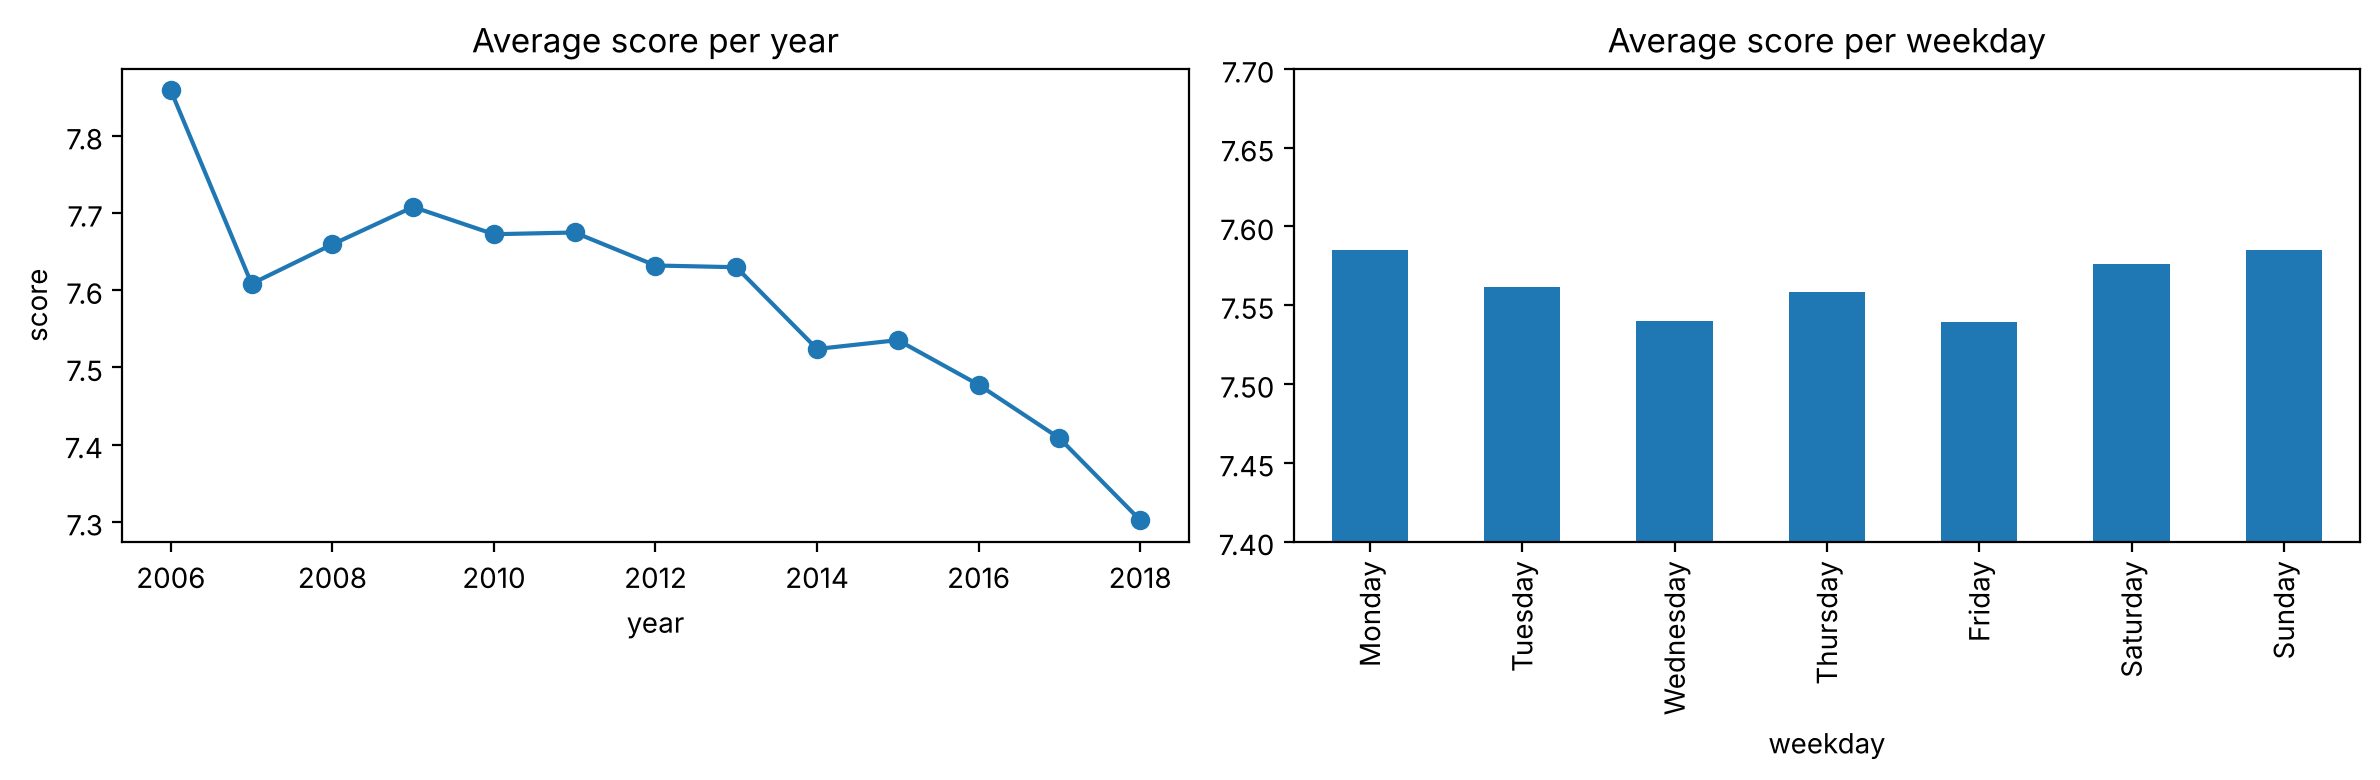

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings_df.groupby("year")["score"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Average score per year")
axes[0].set_ylabel("score")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ratings_df.groupby("weekday")["score"].mean().reindex(order).plot(ax=axes[1], kind="bar")
axes[1].set_ylim(7.4, 7.7)
axes[1].set_title("Average score per weekday")
plt.tight_layout()
plt.show()

**Interpretation**

The score barely depends on weekday or season, but it does depend on the year. All tests are significant, but that's mostly because we have almost a million ratings. The effect sizes tell the real story. Weekend vs weekday has d = 0.014 (7.58 vs 7.56) and the seasons are between -0.03 and 0.02. These are way too small to matter, the plot shows the weekday bars are all around 7.55 to 7.59. The year is different: ratings from 2017 or later are 7.38 on average against 7.60 before, d = -0.125. Still a small effect, but almost 10 times bigger than weekday or season, and it's the same downward trend 02_eda found.

So for predicting the score, weekday and season are not worth using. The year is the only time context with a real effect.

The score is not the whole story though. Context can also change *which* anime people watch, even if the scores stay the same. Below we check how many ratings are on anime that came out at most one year before, and how much the 50 most rated anime change from year to year.

In [18]:
aired_year = anime_df.set_index("anime_id")["aired_from_year"]
ratings_df["anime_age"] = ratings_df["year"] - ratings_df["anime_id"].map(aired_year)

new_share = ratings_df.groupby("year")["anime_age"].apply(lambda a: (a <= 1).mean() * 100)

top50 = {y: set(g["anime_id"].value_counts().head(50).index) for y, g in ratings_df.groupby("year")}
overlap_prev = {y: len(top50[y] & top50[y - 1]) for y in range(2009, 2019)}

season_top50 = {s: set(g["anime_id"].value_counts().head(50).index) for s, g in ratings_df.groupby("season")}

context_items_df = pd.DataFrame({"% ratings on anime from the last year": new_share,
                                 "top 50 shared with previous year": pd.Series(overlap_prev)}).loc[2009:2018]
print("Top 50 shared between seasons (all years together):",
      {f"{a}-{b}": len(season_top50[a] & season_top50[b]) for a, b in [("winter", "spring"), ("spring", "summer"), ("summer", "autumn"), ("autumn", "winter")]})
context_items_df.round(1)

Top 50 shared between seasons (all years together): {'winter-spring': 22, 'spring-summer': 24, 'summer-autumn': 20, 'autumn-winter': 22}


,% ratings on anime from the last year,top 50 shared with previous year
2009,27.9,35.0
2010,30.4,26.0
2011,38.1,21.0
2012,39.0,18.0
2013,42.2,18.0
2014,45.1,10.0
2015,46.4,7.0
2016,45.8,13.0
2017,45.3,9.0
2018,42.1,11.0


**Interpretation**

Time changes *what* people watch much more than how they score it. Around 45% of all ratings since 2014 are on anime that came out at most one year before. And the most rated anime change fast: in recent years only 7 to 13 of the 50 most rated anime of a year were also in the top 50 of the year before. Back in 2009 it was 35. So people mostly watch whatever is new at that moment, and that "new" changes every year.

Seasons also look different (only 20 to 24 of the top 50 shared), but that is mostly the same thing: every season new anime start airing. Our data mixes all years in each season, so season alone doesn't add much on top of the year.

This decides the approach for the rest of the part: the useful context is "what is popular right now", not the weekday or the season.

## The context we evaluate on

The homepage is shown *now*. The data ends in May 2018, so we call "now" the last 12 months of the data. The test ratings from that period are our context test set. The models are still trained on the normal `trainset` from Part 1 (rule 1), we only look at the part of the test set that falls in the context.

In [19]:
data_end = ratings_df["last_updated"].max()
context_start = data_end - pd.Timedelta(days=365)


def add_time(df):
    df = df.copy()
    df["last_updated"] = rating_time.reindex(pd.MultiIndex.from_frame(df[["user_id", "anime_id"]])).values
    return df


test_time_df = add_time(pd.DataFrame(testset, columns=["user_id", "anime_id", "score"]))
train_time_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                      columns=["user_id", "anime_id", "score"]))

in_context = test_time_df["last_updated"] >= context_start
context_testset = list(test_time_df.loc[in_context, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))

# Homepage users: the 1,000 users from Part 1 that liked at least one anime in the context period
liked_in_context = {u for u, i, r in context_testset if r >= relevant_score}
context_users = [u for u in users if u in liked_in_context]

print("Context period:", context_start.date(), "to", data_end.date())
print("Test ratings in the context:", len(context_testset), "of", len(testset))
print("Users with test ratings in the context:", test_time_df.loc[in_context, "user_id"].nunique())
print("Homepage users (of the 1,000) with a liked anime in the context:", len(context_users))

Context period: 2017-05-22 to 2018-05-22
Test ratings in the context: 20570 of 195413
Users with test ratings in the context: 2001
Homepage users (of the 1,000) with a liked anime in the context: 337


Only about 1 in 10 test ratings is from the last year. For the homepage metric we use the users from the 1,000 in Part 1 that have at least one liked anime in that period. Users with nothing in the period would get 0 hits with every model, which would just hide the differences.

## Pre-filtering

Pre-filtering means we filter the training data to the context first, and then train a normal model on it. Here: an SVD trained only on recent ratings. If a user or anime is not in the recent data, we fall back to the SVD trained on everything, otherwise long time users who were not active lately would get nothing.

We try two windows, a short one (last year) and a longer one (last 3 years). Using all years is just the normal SVD.

In [20]:
class MyPreFilterSVD(AlgoBase):
    def __init__(self, start):
        AlgoBase.__init__(self)
        self.start = start

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.global_svd = SVD(random_state=my_seed)
        self.global_svd.fit(trainset)

        # Keep only the training ratings from the context window
        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        recent_df = train_df[train_df["last_updated"] >= self.start]
        self.recent_trainset = Dataset.load_from_df(recent_df[["user_id", "anime_id", "score"]], reader).build_full_trainset()
        self.recent_svd = SVD(random_state=my_seed)
        self.recent_svd.fit(self.recent_trainset)
        self.recent_users = set(recent_df["user_id"])
        self.recent_items = set(recent_df["anime_id"])
        return self

    def estimate(self, u, i):
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            return self.global_svd.estimate(u, i)
        raw_u, raw_i = self.trainset.to_raw_uid(u), self.trainset.to_raw_iid(i)
        if raw_u in self.recent_users and raw_i in self.recent_items:
            return self.recent_svd.predict(raw_u, raw_i).est
        # Fall back to the model trained on all the data
        return self.global_svd.estimate(u, i)

## Post-filtering

Post-filtering does it the other way around. We train the normal SVD on everything and change the ranking afterwards using the context. The tests above showed that the context changes *what* people watch more than the score, so we push up anime that a lot of people rated in the context period:

predicted score with context = SVD score + weight × context popularity

Context popularity is log(1 + number of ratings of the anime in the last year), scaled from 0 to 1. A weight of 0 is the normal SVD.

In [21]:
class MyPostFilterSVD(AlgoBase):
    def __init__(self, start, weight):
        AlgoBase.__init__(self)
        self.start = start
        self.weight = weight

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.svd = SVD(random_state=my_seed)
        self.svd.fit(trainset)

        train_df = add_time(pd.DataFrame([(trainset.to_raw_uid(u), trainset.to_raw_iid(i), r) for (u, i, r) in trainset.all_ratings()],
                                         columns=["user_id", "anime_id", "score"]))
        counts = train_df[train_df["last_updated"] >= self.start].groupby("anime_id").size()
        popularity = np.log1p(counts) / np.log1p(counts.max())
        self.context_popularity = {trainset.to_inner_iid(a): p for a, p in popularity.items()}
        return self

    def estimate(self, u, i):
        return self.svd.estimate(u, i) + self.weight * self.context_popularity.get(i, 0)

### Choosing the weight

The weight is chosen on a validation split taken from the training data (same split as in Part 3), never on the test set. We try very small, middle and very large values, and judge them by the homepage hits on the validation ratings from the context period.

In [22]:
# Same validation split as in Part 3

val_time_df = add_time(pd.DataFrame(tune_valset, columns=["user_id", "anime_id", "score"]))
context_valset = list(val_time_df.loc[val_time_df["last_updated"] >= context_start, ["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
val_liked = {u for u, i, r in context_valset if r >= relevant_score}
val_context_users = [u for u in eval_users(tune_trainset, n=1000) if u in val_liked]
print("Validation users with a liked anime in the context:", len(val_context_users))

tuning_rows = []
for weight in [0, 0.5, 1, 3, 10]:
    algo = MyPostFilterSVD(context_start, weight)
    algo.fit(tune_trainset)
    top_n = top_n_unseen(algo, tune_trainset, val_context_users, solve_ties=True)
    row = {"weight": weight}
    row.update(homepage_hits(top_n, context_valset))
    row["RMSE"] = accuracy_metrics(algo.test(context_valset))["RMSE"]
    tuning_rows.append(row)

weight_tuning_df = pd.DataFrame(tuning_rows).set_index("weight")
best_post_weight = weight_tuning_df["hits out of 10"].idxmax()
print("Best weight:", best_post_weight)
weight_tuning_df.round(3)

Validation users with a liked anime in the context: 274


Best weight: 1.0


,hits out of 10,users with at least 1 hit %,RMSE
weight,,,
0.0,0.124,10.584,1.251
0.5,0.157,13.139,1.289
1.0,0.208,18.248,1.388
3.0,0.088,7.299,2.008
10.0,0.015,1.460,2.921


**Interpretation**

A weight of 1 is the best on validation: 0.208 hits per 10 against 0.124 for the plain SVD (weight 0). Too much weight is bad. At 3 the hits drop to 0.088 and at 10 to 0.015, because then the list is basically just "most watched last year" and the user's own taste is ignored. The RMSE goes up with every weight, which makes sense since we add something to the predicted score on purpose. We care about the ranking on the homepage here, not the exact score.

## Results on the context test set

Same metrics as the other parts (rules 3 and 4), but on the test ratings from the last year. Random (the current homepage) and Bayesian popular (the baseline from Part 2) are included to compare. The Bayesian popular class is copied from Part 2 so this draft runs on its own, it can be removed when the parts are put together.

In [23]:
part6_models = {
    "Random": MyRandomAlgorithm(),
    "Bayesian popular": MyBayesianPopularAlgorithm(),
    "SVD (no context)": SVD(random_state=my_seed),
    "Pre-filter SVD, 1 year": MyPreFilterSVD(context_start),
    "Pre-filter SVD, 3 years": MyPreFilterSVD(data_end - pd.Timedelta(days=3 * 365)),
    f"Post-filter SVD, weight {best_post_weight}": MyPostFilterSVD(context_start, best_post_weight),
}

part6_results = defaultdict(dict)
part6_top_n = {}
for name, algo in part6_models.items():
    algo.fit(trainset)
    predictions = algo.test(context_testset)
    part6_results[name].update(accuracy_metrics(predictions))
    part6_results[name].update(test_ranking_metrics(predictions))
    part6_results[name]["NDCG@10 (20+ test items)"] = test_ranking_metrics(predictions, min_test_items=20)["NDCG@10"]
    top_n = top_n_unseen(algo, trainset, context_users, solve_ties=(name != "Random"))
    part6_top_n[name] = top_n
    part6_results[name].update(homepage_hits(top_n, context_testset))

results_part6_df = pd.DataFrame(part6_results).T
results_part6_df.round(3)

,RMSE,MAE,NDCG@10,MAP@10,MAR@10,users,NDCG@10 (20+ test items),hits out of 10,users with at least 1 hit %
Random,2.392,1.880,0.925,0.696,0.668,2001.0,0.810,0.021,1.780
Bayesian popular,1.652,1.221,0.965,0.846,0.804,2001.0,0.909,0.297,22.255
SVD (no context),1.229,0.910,0.969,0.857,0.813,2001.0,0.923,0.234,18.398
"Pre-filter SVD, 1 year",1.266,0.947,0.965,0.846,0.804,2001.0,0.911,0.231,18.398
"Pre-filter SVD, 3 years",1.235,0.916,0.968,0.858,0.814,2001.0,0.917,0.231,18.398
"Post-filter SVD, weight 1.0",1.377,1.031,0.969,0.861,0.817,2001.0,0.924,0.380,27.893


**Interpretation**

Post-filtering is the clear winner for users visiting now. It finds 0.380 liked anime per 10 shown, against 0.234 for the SVD without context. That's about 62% more. 27.9% of users get at least one hit, against 18.4%. It also beats Bayesian popular (0.297), which the plain SVD does not. Random gets 0.021, so the post-filter shows about 18 times more liked anime than the current homepage.

**Pre-filtering does not help.** Training only on the last year gives 0.231 hits and a worse RMSE (1.266 against 1.229). Using 3 years is almost the same as the normal SVD. Our guess is that cutting the data throws away too much: the last year only has about 81,000 training ratings, around a tenth of everything, so the model learns the users' taste worse. The post-filter keeps all the data to learn the taste and only uses the context to change the order at the end.

The ranking metrics on the test items (NDCG, MAP, MAR) are almost the same for all the SVD models. Like in Part 1, these only rank each user's own test ratings, so they don't show the difference. The homepage metric does.

The RMSE of the post-filter is worse (1.377), which is expected because we add the context boost to the score. It's a ranking model now, not a score predictor.

### Coverage, personalization and diversity

Rule 5: these use `full_trainset` and the 1,000 users from Part 1. We only run them for the SVD without context and the post-filter, since the question is what the context does to the lists.

In [24]:
part6_beyond = {}
for name in ["SVD (no context)", f"Post-filter SVD, weight {best_post_weight}"]:
    algo = part6_models[name]
    algo.fit(full_trainset)
    top_n = top_n_unseen(algo, full_trainset, full_users, solve_ties=True)
    part6_beyond[name] = beyond_accuracy_metrics(top_n, full_trainset)
    # how new are the anime we show? (year the anime started airing)
    shown = [i for items in top_n.values() for i in items]
    part6_beyond[name]["median aired year of shown anime"] = aired_year.reindex(shown).median()

pd.DataFrame(part6_beyond).T.round(3)

,coverage %,personalization,intra-list similarity,median aired year of shown anime
SVD (no context),13.27,0.911,0.268,2012.0
"Post-filter SVD, weight 1.0",9.61,0.854,0.246,2017.0


**Interpretation**

Trade-off: more recent and a little more genre diversity, but lower coverage. Post-filter: median start year 2017 instead of 2012, a little more genre diversity (similarity within list 0.246 instead of 0.268), but coverage goes down (9.6% instead of 13.3%) and personalization too (0.854 instead of 0.911), because more users get the same recent anime. Small step towards the popular list. Most of the list (weight 1) is still personalized, but it's something to keep an eye on, since showing less of the older anime that the platform buys is probably not good.

## CVTT

The random split lets the models learn from the future (see 1.3), which is an issue for a part about time. We cross-validate through time (CVTT) with the folds from Part 1: train on the past, test on the next period. In each fold "now" is the last 12 months of the training fold. For speed we use 300 random users per fold for the homepage metric.

In [25]:
cvtt_rows = []
for fold, (train_index, test_index) in enumerate(tscv.split(ratings_by_time_df), start=1):
    train_fold = ratings_by_time_df.loc[train_index]
    test_fold = ratings_by_time_df.loc[test_index]
    fold_trainset = Dataset.load_from_df(train_fold[["user_id", "anime_id", "score"]], reader).build_full_trainset()
    fold_testset = list(test_fold[["user_id", "anime_id", "score"]].itertuples(index=False, name=None))
    fold_now = train_fold["last_updated"].max() - pd.Timedelta(days=365)

    # Homepage users: known in training and liked something in the test fold
    liked = set(test_fold.loc[test_fold["score"] >= relevant_score, "user_id"]) & set(train_fold["user_id"])
    rng = np.random.default_rng(my_seed)
    fold_users = list(rng.choice(sorted(liked), size=min(300, len(liked)), replace=False))

    for name, algo in {"SVD (no context)": SVD(random_state=my_seed),
                       "Pre-filter SVD, 1 year": MyPreFilterSVD(fold_now),
                       f"Post-filter SVD, weight {best_post_weight}": MyPostFilterSVD(fold_now, best_post_weight)}.items():
        algo.fit(fold_trainset)
        predictions = algo.test(fold_testset)
        row = {"fold": fold, "model": name, "RMSE": accuracy_metrics(predictions)["RMSE"]}
        row.update(homepage_hits(top_n_unseen(algo, fold_trainset, fold_users, solve_ties=True), fold_testset))
        cvtt_rows.append(row)

cvtt_df = pd.DataFrame(cvtt_rows)
cvtt_df.pivot(index="fold", columns="model", values="hits out of 10").round(3)

model,"Post-filter SVD, weight 1.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,
1,0.980,0.867,0.817
2,0.953,0.727,0.760
3,0.840,0.693,0.687
4,0.740,0.567,0.563
5,1.230,0.917,0.963


In [26]:
cvtt_df.pivot(index="fold", columns="model", values="RMSE").round(3)

model,"Post-filter SVD, weight 1.0","Pre-filter SVD, 1 year",SVD (no context)
fold,,,
1,1.663,1.541,1.541
2,1.611,1.497,1.494
3,1.625,1.526,1.518
4,1.591,1.484,1.475
5,1.608,1.498,1.494


**Interpretation**

CVTT confirms the result. In all 5 folds the post-filter gets more homepage hits than the SVD without context, 0.74 to 1.23 against 0.56 to 0.96 per 10 (about 20 to 30% more). The pre-filter is about the same as the normal SVD again. Higher hits than the random split because here the test fold has all the future ratings of a user instead of 20% of them.

More honest test for a part about time, because the models can't learn from the future. Gain a little lower than for the random split, but it's there every time. Same as before, RMSE is worse for the post-filter (about 1.6 against 1.5) for the same reason.

## Example: one user's homepage

This is the top 10 of one context user with the normal SVD and with the post-filter. A ✓ means the user rated the anime 8 or more in the test set.

In [27]:
liked_test = defaultdict(set)
for u, i, r in context_testset:
    if r >= relevant_score:
        liked_test[u].add(i)

post_name = f"Post-filter SVD, weight {best_post_weight}"
# Pick the user where the post-filter gains the most hits
gain = {u: len(set(part6_top_n[post_name][u]) & liked_test[u]) - len(set(part6_top_n["SVD (no context)"][u]) & liked_test[u]) for u in context_users}
context_example_user = max(gain, key=gain.get)

def show(items):
    return [titles[i] + (" ✓" if i in liked_test[context_example_user] else "") for i in items]

pd.DataFrame({"SVD (no context)": show(part6_top_n["SVD (no context)"][context_example_user]),
              "Post-filter": show(part6_top_n[post_name][context_example_user])}, index=range(1, 11))

,SVD (no context),Post-filter
1,Fullmetal Alchemist: Brotherhood,Fullmetal Alchemist: Brotherhood
2,Steins;Gate 0,3-gatsu no Lion 2nd Season
3,Baccano! Specials,Steins;Gate 0
4,Uchuu Senkan Yamato 2199,Made in Abyss ✓
5,3-gatsu no Lion 2nd Season,Baccano! Specials
6,Beck,Kizumonogatari III: Reiketsu-hen
7,Ashita no Joe 2,Shigatsu wa Kimi no Uso
8,Major: World Series,NHK ni Youkoso!
9,Romeo no Aoi Sora,Beck
10,NHK ni Youkoso!,Gintama.: Shirogane no Tamashii-hen ✓


**Interpretation**

Without context we see a lot of older anime (Ashita no Joe 2, Romeo no Aoi Sora, Uchuu Senkan Yamato 2199). With the post-filter recent anime appears like Made in Abyss and the new Gintama season, and this user did like both. Fullmetal Alchemist: Brotherhood stays number 1 in both lists, so this user's taste is still there. The post-filter only moves the recent anime up.

This is the user where the post-filter gains the most, so it's a best case, but it illustrates very well what the context does.

## Conclusion of Part 6

**Conclusion**

- Weekday and season don't seem to change the score much (d below 0.03), so we don't use them. Year has more of an impact, and especially time changes what anime people watch: almost half the ratings are on anime from the last year.
- Pre-filtering (training only on recent data) doesn't help because it wastes most of the data.
- Post-filtering (normal SVD + boost for anime that are popular right now, weight 1) gives about 62% more liked anime on the homepage than the same SVD without context, and also beats Bayesian popular. CVTT confirms it in all 5 folds.
- Lower coverage (13.3% to 9.6%) and a little less personalization. The lists are more recent and slightly more diverse in genre.

**Business-wise**, a user who opens the app today has 0.38 anime they like in the top 10 instead of 0.23, and 28% of them find at least one instead of 18%. Compared with the random homepage it's about 18 times more. The model doesn't need any new data, only the dates we already have.

**Limitations:** `last_updated` is the last edit, not the watch date, the "now" period is only about 1 in 10 test ratings, and the weight was tuned on one validation split. It should be tested online before using it, for example in the A/B test from Part 8.

**For Part 5 and Part 8**, the post-filter can be used on top of whatever CF model wins in Part 3, it doesn't have to be SVD. In the hybrid it would be the last step before showing the homepage.

# Part 7. Bandits

To be added.

# Part 8. Final comparison and business value

To be added.

# References

[1] Aggarwal, C. C. (2016). Recommender Systems: The Textbook. Springer.

[2] Falk, K. (2019). Practical Recommender Systems. Manning.

[3] S05 notebook. Key data for building recommendation systems.

[4] S08 notebook. Practical exercises on performance metrics.

[5] S10 notebook. Data splitting and evaluation methods.

[6] S20 notebook. Offline vs online evaluation, hyperparameter tuning and A/B testing strategy.

[7] Impact of long-tail into performance metrics notebook.

[8] Class notes, Session 16.

[9] A4 Build your own non-personalized recommender (assignment brief).

[10] Google Colab. Past runtime versions FAQ. https://research.google.com/colaboratory/runtime-version-faq.html

[11] A3 Expected performance of non-personalized recommenders (assignment brief).

[12] S06 slides. Approaches to building recommenders: collaborative, content-based and hybrid.

[13] S09 notebook. Building non-personalized recommenders.

[14] Class notes, Sessions 1 to 18.